# Telco Customer Churn: Master Notebook (Week 1, Tân's tasks)

**Owner of this file:** Tân (Lead Pipeline & Explainability) · **Course:** Statistical Learning · **Dataset:** Telco Customer Churn (7,043 customers, 21 columns)

This notebook covers Tân's Week 1 tasks only. Everything the team shares (constants, cleaning rules, the 80/20 split, the preprocessing recipe, metric helpers) is defined **once, in Section 1**. There is no separate `churn_core.py`: every cell below Section 1 can use those names directly, and Yến and NMinh can append their sections to the end of this file.

| Section | Content | Task in the tracker PDF |
|---|---|---|
| 1 | Shared toolkit | shared by all |
| 2 and 3 | Raw-data audit and deterministic cleaning | Task 1.2 |
| 4 | Stratified 80/20 split | needed here so EDA can use the train set only |
| 5 | Descriptive statistics, boxplots, churn distribution, Chi-square and Cramér's V (train only) | Task 1.3 |

Run with **Kernel → Restart & Run All**.

## 1. Shared toolkit

Section 1 is split into five cells: imports and paths, cleaning, the split, the preprocessing pipeline, and metric helpers. The last two are not used in this notebook; they are included so teammates can use them. Nothing here depends on the data being loaded yet, so the whole section only defines names.

**Where the files go.** The notebook looks for the raw CSV in `data/raw/telco_customer_churn.csv`, then next to the notebook (`telco_customer_churn.csv` or the original Kaggle name `WA_Fn-UseC_-Telco-Customer-Churn.csv`). Outputs are written to `data/processed/`, `artifacts/` and `reports/figures/`, which are created automatically.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "telco_customer_churn.csv",
    PROJECT_ROOT / "telco_customer_churn.csv",
    PROJECT_ROOT / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
RAW_DATA_PATH = next((path for path in RAW_DATA_CANDIDATES if path.exists()), None)
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
for folder in (PROCESSED_DIR, ARTIFACTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_CV_FOLDS = 5
SIGNIFICANCE_LEVEL = 0.05

ID_COLUMN = "customerID"
TARGET_COLUMN = "Churn"
NUMERIC_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_FEATURES = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
INTERNET_DEPENDENT_FEATURES = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
SKLEARN_VERSION = tuple(int(part) for part in sklearn.__version__.split(".")[:2])

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
def load_raw_customers(path=RAW_DATA_PATH):
    """Read the original CSV without changing anything."""
    if path is None:
        searched = "\n".join(str(candidate) for candidate in RAW_DATA_CANDIDATES)
        raise FileNotFoundError(f"Raw CSV not found. Put it in one of:\n{searched}")
    return pd.read_csv(path)


def clean_customers(customers_raw):
    """Return a cleaned copy indexed by customerID.

    Rules fixed by business logic (not estimated from data), so applying them
    before the split cannot leak test information: strip whitespace, convert
    TotalCharges to float, set the blank TotalCharges of never-billed customers
    (tenure == 0) to 0, and merge "No internet service" / "No phone service" into "No".
    """
    if customers_raw[ID_COLUMN].duplicated().any():
        raise ValueError("customerID must be unique.")

    customers = customers_raw.copy()
    for column in customers.select_dtypes(exclude="number").columns:
        customers[column] = customers[column].str.strip()

    total_charges_is_blank = customers["TotalCharges"].eq("")
    customer_never_billed = customers["tenure"].eq(0)
    if not total_charges_is_blank.equals(customer_never_billed):
        raise ValueError("Blank TotalCharges no longer matches tenure == 0.")

    total_charges = pd.to_numeric(
        customers["TotalCharges"].where(~total_charges_is_blank), errors="raise"
    )
    customers["TotalCharges"] = total_charges.fillna(0.0).astype("float64")

    merge_redundant_service_labels(customers)
    return customers.set_index(ID_COLUMN)


def merge_redundant_service_labels(customers):
    """Replace "No internet service" / "No phone service" by "No", in place."""
    redundant_label_rules = [
        (INTERNET_DEPENDENT_FEATURES, "No internet service", customers["InternetService"].eq("No")),
        (["MultipleLines"], "No phone service", customers["PhoneService"].eq("No")),
    ]
    for columns, redundant_label, implied_by_other_column in redundant_label_rules:
        for column in columns:
            if not customers[column].eq(redundant_label).equals(implied_by_other_column):
                raise ValueError(f"'{redundant_label}' in {column} is not fully implied by another column.")
            customers[column] = customers[column].replace(redundant_label, "No")

In [3]:
def split_train_test(customers):
    """Stratified 80/20 split shared by the whole team.

    Returns X_train, X_test, y_train, y_test where y is 1 for churn, 0 otherwise.
    """
    features = customers[ALL_FEATURES]
    target = customers[TARGET_COLUMN].map({"No": 0, "Yes": 1}).astype("int64")
    return train_test_split(
        features, target,
        test_size=TEST_SIZE, stratify=target, random_state=RANDOM_STATE,
    )

In [4]:
def build_preprocessor():
    """Unfitted ColumnTransformer: scale numeric, one-hot encode categorical.

    Always place it inside a Pipeline so fit() only sees training data,
    including inside every cross-validation fold.
    """
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            (
                "categorical",
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return preprocessor.set_output(transform="pandas")


def build_model_pipeline(estimator):
    """Preprocessing + estimator as one object, ready for fit/predict/GridSearchCV."""
    return Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])


def get_feature_names(fitted_pipeline):
    """Column names produced by the fitted preprocessing step."""
    return list(fitted_pipeline.named_steps["preprocess"].get_feature_names_out())

In [5]:
def compute_basic_metrics(y_true, y_pred):
    """Accuracy and churn-class (label 1) precision, recall, F1."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def make_logistic_regression(penalty, C=1.0):
    """L1 or L2 logistic regression that runs without warnings on scikit-learn 1.2+.

    scikit-learn 1.8 replaced `penalty` with `l1_ratio` (1.0 means L1, 0.0 means L2).
    liblinear supports both penalties on this small dataset.
    """
    if penalty not in ("l1", "l2"):
        raise ValueError("penalty must be 'l1' or 'l2'.")
    if SKLEARN_VERSION >= (1, 8):
        penalty_settings = {"l1_ratio": 1.0 if penalty == "l1" else 0.0}
    else:
        penalty_settings = {"penalty": penalty}
    return LogisticRegression(
        C=C, solver="liblinear", max_iter=1000, random_state=RANDOM_STATE, **penalty_settings
    )

## 2. Load and audit the raw data

The raw file is loaded untouched first. The audit looks for problems that `isna()` alone cannot see: blank strings, duplicates, inconsistent labels and impossible values. Each finding either justifies a cleaning rule or is recorded as "checked, nothing to do".

In [6]:
customers_raw = load_raw_customers()
print(f"Rows: {customers_raw.shape[0]:,} | Columns: {customers_raw.shape[1]}")
customers_raw.head()

Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [7]:
customers_raw.dtypes.to_frame("raw_dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
raw_dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


`TotalCharges` is stored as text although it holds money amounts, so it must contain at least one non-numeric entry. The next cell counts missing values in two ways: real `NaN` and blank text.

In [8]:
text_columns = customers_raw.select_dtypes(exclude="number")
missing_overview = pd.DataFrame({
    "nan_count": customers_raw.isna().sum(),
    "blank_text_count": text_columns.apply(lambda column: column.str.strip().eq("").sum()),
}).fillna(0).astype(int)
missing_overview[missing_overview.sum(axis=1) > 0]

,nan_count,blank_text_count
TotalCharges,0,11


`isna()` reports no missing values, yet 11 `TotalCharges` cells are blank text. Here are those customers.

In [9]:
blank_total_charges = customers_raw[customers_raw["TotalCharges"].str.strip().eq("")]
display(blank_total_charges[["tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

print("Every blank row has tenure == 0:", blank_total_charges["tenure"].eq(0).all())
print("Rows with tenure == 0 in the whole dataset:", customers_raw["tenure"].eq(0).sum())
print("Churn labels among blank rows:", blank_total_charges["Churn"].value_counts().to_dict())

,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,0,52.5500,,Two year,No
753,0,20.2500,,Two year,No
936,0,80.8500,,Two year,No
1082,0,25.7500,,Two year,No
1340,0,56.0500,,Two year,No
3331,0,19.8500,,Two year,No
3826,0,25.3500,,Two year,No
4380,0,20.0000,,Two year,No
5218,0,19.7000,,One year,No
6670,0,73.3500,,Two year,No


Every blank row has tenure == 0: True
Rows with tenure == 0 in the whole dataset: 11
Churn labels among blank rows: {'No': 11}


**Finding.** The 11 blank cells are exactly the 11 customers with `tenure == 0`. They have just signed up and have not received a first bill, so the true total charged is 0. Setting `TotalCharges = 0` is therefore a factual correction rather than an estimate, and it needs no statistics from the data. That is why it is safe to apply before the train/test split.

In [10]:
duplicated_ids = customers_raw["customerID"].duplicated().sum()
rows_identical_except_id = customers_raw.drop(columns="customerID").duplicated().sum()
print("Duplicated customerID:", duplicated_ids)
print("Rows identical in every column except customerID:", rows_identical_except_id)

Duplicated customerID: 0
Rows identical in every column except customerID: 22


Customer IDs are unique, so no customer appears twice. A small number of different customers share an identical profile, which is expected when 16 of 19 features are categorical. These rows are kept.

In [11]:
for column in CATEGORICAL_FEATURES:
    print(f"{column:<18}", sorted(customers_raw[column].unique()))
customers_raw[["tenure", "MonthlyCharges"]].describe()

gender             ['Female', 'Male']
SeniorCitizen      [np.int64(0), np.int64(1)]
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


,tenure,MonthlyCharges
count,7043.0000,7043.0000
mean,32.3711,64.7617
std,24.5595,30.0900
min,0.0000,18.2500
25%,9.0000,35.5000
50%,29.0000,70.3500
75%,55.0000,89.8500
max,72.0000,118.7500


Labels are spelled consistently (no case or spacing variants), `SeniorCitizen` is strictly 0/1, `tenure` is within 0 to 72 months and `MonthlyCharges` is positive. The last structural check confirms that the "No internet service" and "No phone service" labels appear exactly when they logically must. If they do, they carry no information beyond `InternetService == "No"` and `PhoneService == "No"`.

In [12]:
internet_dependent_columns = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
has_no_internet = customers_raw["InternetService"].eq("No")
has_no_phone = customers_raw["PhoneService"].eq("No")

consistency_checks = {
    f"{column}: 'No internet service' iff InternetService == 'No'":
        customers_raw[column].eq("No internet service").equals(has_no_internet)
    for column in internet_dependent_columns
}
consistency_checks["MultipleLines: 'No phone service' iff PhoneService == 'No'"] = (
    customers_raw["MultipleLines"].eq("No phone service").equals(has_no_phone)
)
consistency_checks["SeniorCitizen only contains 0 and 1"] = set(customers_raw["SeniorCitizen"]) == {0, 1}
consistency_checks["tenure within 0..72"] = customers_raw["tenure"].between(0, 72).all()
consistency_checks["MonthlyCharges > 0"] = customers_raw["MonthlyCharges"].gt(0).all()

pd.Series(consistency_checks, name="passed").to_frame()

,passed
OnlineSecurity: 'No internet service' iff InternetService == 'No',True
OnlineBackup: 'No internet service' iff InternetService == 'No',True
DeviceProtection: 'No internet service' iff InternetService == 'No',True
TechSupport: 'No internet service' iff InternetService == 'No',True
StreamingTV: 'No internet service' iff InternetService == 'No',True
StreamingMovies: 'No internet service' iff InternetService == 'No',True
MultipleLines: 'No phone service' iff PhoneService == 'No',True
SeniorCitizen only contains 0 and 1,True
tenure within 0..72,True
MonthlyCharges > 0,True


In [13]:
assert all(consistency_checks.values())

total_charges_numeric = pd.to_numeric(customers_raw["TotalCharges"], errors="coerce")
billed_customers = customers_raw["tenure"].gt(0)
expected_total = customers_raw["tenure"] * customers_raw["MonthlyCharges"]
relative_gap = ((total_charges_numeric - expected_total).abs() / expected_total)[billed_customers]
relative_gap.describe(percentiles=[0.5, 0.95]).to_frame("|TotalCharges - tenure x MonthlyCharges| / expected")

,|TotalCharges - tenure x MonthlyCharges| / expected
count,7032.0000
mean,0.0320
std,0.0399
min,0.0000
50%,0.0200
95%,0.1032
max,0.5735


`TotalCharges` is close to `tenure × MonthlyCharges` for most customers (median gap about 2%), with larger gaps for customers whose price changed over time. This means `TotalCharges` is largely a product of the other two numeric features, so strong correlation among them is expected. It matters later when coefficients are interpreted.

## 3. Clean the data (tracker Task 1.2)

`clean_customers()` (Section 1) performs four steps:

1. Strip stray whitespace from text columns.
2. Convert `TotalCharges` to `float` and fill the 11 blanks with 0.
3. Merge "No internet service" and "No phone service" into "No" in the 7 dependent service columns. The audit proved these labels only repeat `InternetService == "No"` and `PhoneService == "No"`. Left in place, the six internet-service columns would become identical dummy columns, and a regression would split their effect between them arbitrarily.
4. Use `customerID` as the row index, so any row can be traced back to a customer (needed later for SHAP waterfall plots).

The function raises an error if the blank cells stop matching `tenure == 0` or if a redundant label is not fully implied by another column, so a changed dataset cannot be cleaned silently.

In [14]:
customers = clean_customers(customers_raw)

assert len(customers) == len(customers_raw)
assert customers["TotalCharges"].dtype == "float64"
assert customers.isna().sum().sum() == 0
assert customers.loc[customers["tenure"].eq(0), "TotalCharges"].eq(0).all()
assert all(customers[column].nunique() == 2 for column in INTERNET_DEPENDENT_FEATURES + ["MultipleLines"])

cleaning_summary = pd.DataFrame({
    "before": {
        "TotalCharges dtype": str(customers_raw["TotalCharges"].dtype),
        "blank TotalCharges cells": int(customers_raw["TotalCharges"].str.strip().eq("").sum()),
        "rows": len(customers_raw),
        "labels in OnlineSecurity": customers_raw["OnlineSecurity"].nunique(),
    },
    "after": {
        "TotalCharges dtype": str(customers["TotalCharges"].dtype),
        "blank TotalCharges cells": int(customers["TotalCharges"].isna().sum()),
        "rows": len(customers),
        "labels in OnlineSecurity": customers["OnlineSecurity"].nunique(),
    },
})
cleaning_summary

,before,after
TotalCharges dtype,str,float64
blank TotalCharges cells,11,0
rows,7043,7043
labels in OnlineSecurity,3,2


## 4. Stratified train/test split

The target is imbalanced (about 26.5% churn), so a random split could shift that ratio and the split must be stratified. `split_train_test()` uses `test_size=0.20`, `stratify=y` and `random_state=42` (constants from Section 1), so every member gets the identical split.

From this point on the test set is locked: all exploration below uses `X_train` and `y_train` only.

In [15]:
X_train, X_test, y_train, y_test = split_train_test(customers)

split_overview = pd.DataFrame(
    {"rows": [len(y_train), len(y_test)], "churn_rate": [y_train.mean(), y_test.mean()]},
    index=["train", "test"],
)
assert set(X_train.index).isdisjoint(X_test.index)
assert abs(y_train.mean() - y_test.mean()) < 0.001
split_overview

,rows,churn_rate
train,5634,0.2654
test,1409,0.2654


In [16]:
X_train.join(y_train).to_csv(PROCESSED_DIR / "train.csv")
X_test.join(y_test).to_csv(PROCESSED_DIR / "test.csv")

## 5. Descriptive statistics and inferential tests (tracker Task 1.3, train set only)

Nothing in this section touches `X_test`. `train_df` is the training features joined with the target `Churn` (1 = churned).

In [17]:
train_df = X_train.join(y_train)
print(f"train_df: {train_df.shape[0]:,} rows, {train_df.shape[1]} columns")

train_df: 5,634 rows, 20 columns


### 5.1 Mean, median, skewness, kurtosis and IQR

In [18]:
first_quartile = train_df[NUMERIC_FEATURES].quantile(0.25)
third_quartile = train_df[NUMERIC_FEATURES].quantile(0.75)
interquartile_range = third_quartile - first_quartile
lower_fence = first_quartile - 1.5 * interquartile_range
upper_fence = third_quartile + 1.5 * interquartile_range

outlier_count = pd.Series({
    column: ((train_df[column] < lower_fence[column]) | (train_df[column] > upper_fence[column])).sum()
    for column in NUMERIC_FEATURES
})

descriptive_stats = pd.DataFrame({
    "mean": train_df[NUMERIC_FEATURES].mean(),
    "median": train_df[NUMERIC_FEATURES].median(),
    "std": train_df[NUMERIC_FEATURES].std(),
    "skewness": train_df[NUMERIC_FEATURES].skew(),
    "excess_kurtosis": train_df[NUMERIC_FEATURES].kurt(),
    "iqr": interquartile_range,
    "outliers": outlier_count,
})
descriptive_stats.to_csv(ARTIFACTS_DIR / "eda_descriptive_stats.csv")
descriptive_stats

,mean,median,std,skewness,excess_kurtosis,iqr,outliers
tenure,32.4851,29.0000,24.5687,0.2374,-1.3873,46.0000,0
MonthlyCharges,64.9300,70.5000,30.1381,-0.2244,-1.2604,54.3375,0
TotalCharges,2299.3347,1394.9250,2279.2043,0.9490,-0.2646,3432.8500,0


**Reading the table.** `TotalCharges` is right-skewed (skewness 0.95, mean 2,299 above median 1,395) because many customers are recent and have been billed for only a few months. `tenure` and `MonthlyCharges` are close to symmetric (skewness between -0.25 and 0.25) and flatter than a normal curve (excess kurtosis about -1.4 and -1.3). No feature has a single point outside the 1.5 × IQR fences, so no outlier removal is needed, and `StandardScaler` in the pipeline is enough to put the three features on one scale.

### 5.2 Boxplots (IQR rule)

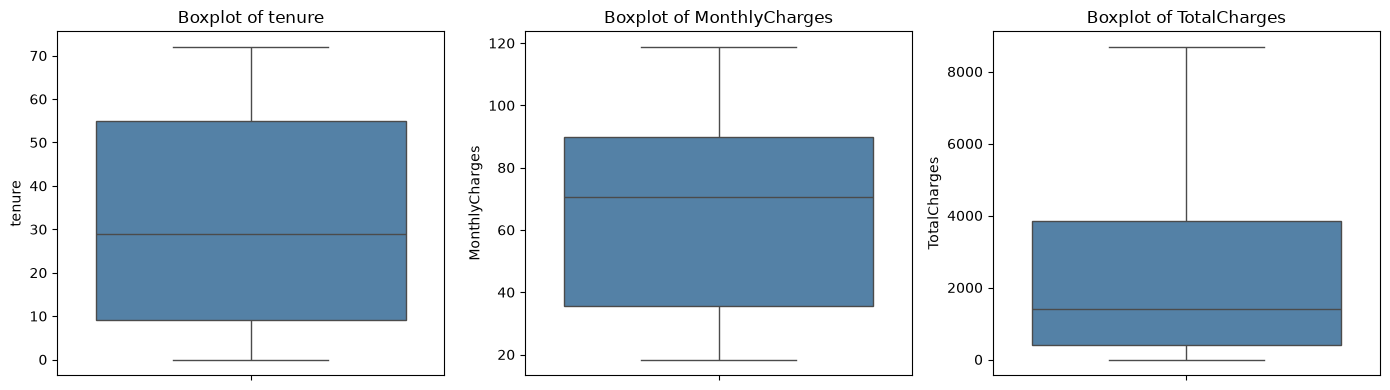

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(y=train_df[column], ax=axis, color="steelblue")
    axis.set_title(f"Boxplot of {column}")
    axis.set_ylabel(column)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_boxplots.png", dpi=200)
plt.show()

### 5.3 Correlation between the numeric features

In [20]:
train_df[NUMERIC_FEATURES].corr().round(3)

,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2570,0.8300
MonthlyCharges,0.2570,1.0000,0.6540
TotalCharges,0.8300,0.6540,1.0000


`TotalCharges` correlates strongly with `tenure` (0.83) and clearly with `MonthlyCharges` (0.65), as expected from the audit: it is roughly their product. This overlap is worth remembering later: strongly correlated features make regression coefficients harder to interpret.

### 5.4 Churn distribution

In [21]:
churn_summary = pd.DataFrame({
    "count": y_train.value_counts(),
    "percent": y_train.value_counts(normalize=True) * 100,
}).sort_index().rename(index={0: "No", 1: "Yes"})
churn_summary

,count,percent
Churn,,
No,4139,73.4647
Yes,1495,26.5353


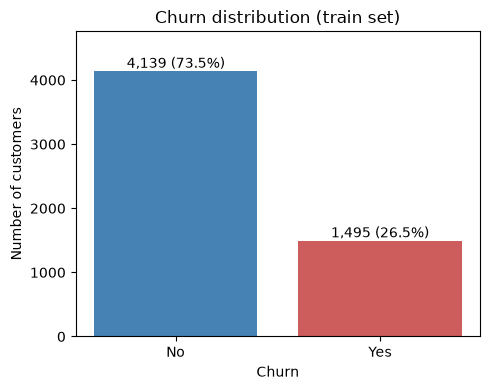

In [22]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(churn_summary.index, churn_summary["count"], color=["steelblue", "indianred"])
ax.bar_label(bars, labels=[f"{count:,} ({percent:.1f}%)" for count, percent in churn_summary.itertuples(index=False)])
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.set_title("Churn distribution (train set)")
ax.set_ylim(0, churn_summary["count"].max() * 1.15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_churn_distribution.png", dpi=200)
plt.show()

The train set has 4,139 non-churners (73.5%) and 1,495 churners (26.5%). With this imbalance a model that always predicts "No" already reaches about 73.5% accuracy while finding no churner, so accuracy alone is misleading and the baselines report recall and F1 for the churn class. It also justifies the stratified split in Section 4 and the later comparison of SMOTE against class weights.

### 5.5 Chi-square test and Cramér's V for the 16 categorical features

For each feature the test compares its distribution across churned and non-churned customers. Cramér's V rescales the Chi-square statistic to the range 0 to 1 so features with different numbers of categories can be ranked: $V = \sqrt{\chi^2 / (n \cdot \min(r-1, c-1))}$. The p-value uses the standard Chi-square test; V is computed from the uncorrected statistic (`correction=False`), the textbook definition.

In [23]:
def cramers_v(contingency_table):
    chi2_statistic = chi2_contingency(contingency_table, correction=False)[0]
    total_observations = contingency_table.to_numpy().sum()
    smaller_dimension = min(contingency_table.shape) - 1
    return np.sqrt(chi2_statistic / (total_observations * smaller_dimension))

In [24]:
association_rows = []
for feature in CATEGORICAL_FEATURES:
    contingency_table = pd.crosstab(train_df[feature], train_df[TARGET_COLUMN])
    chi2_statistic, p_value, degrees_of_freedom, _ = chi2_contingency(contingency_table)
    association_rows.append({
        "feature": feature,
        "chi2": chi2_statistic,
        "dof": degrees_of_freedom,
        "p_value": p_value,
        "cramers_v": cramers_v(contingency_table),
        "significant": p_value < SIGNIFICANCE_LEVEL,
    })

association_table = (
    pd.DataFrame(association_rows)
    .sort_values("cramers_v", ascending=False)
    .reset_index(drop=True)
)
association_table.to_csv(ARTIFACTS_DIR / "eda_chi2_cramers_v.csv", index=False)
association_table

,feature,chi2,dof,p_value,cramers_v,significant
0,Contract,952.3080,2,0.0000,0.4111,True
1,InternetService,600.8466,2,0.0000,0.3266,True
2,PaymentMethod,545.2144,3,0.0000,0.3111,True
3,PaperlessBilling,219.9225,1,0.0000,0.1980,True
4,OnlineSecurity,170.8442,1,0.0000,0.1746,True
5,Dependents,157.1637,1,0.0000,0.1675,True
6,TechSupport,153.9081,1,0.0000,0.1657,True
7,Partner,118.9693,1,0.0000,0.1457,True
8,SeniorCitizen,118.5457,1,0.0000,0.1456,True
9,OnlineBackup,37.8896,1,0.0000,0.0824,True


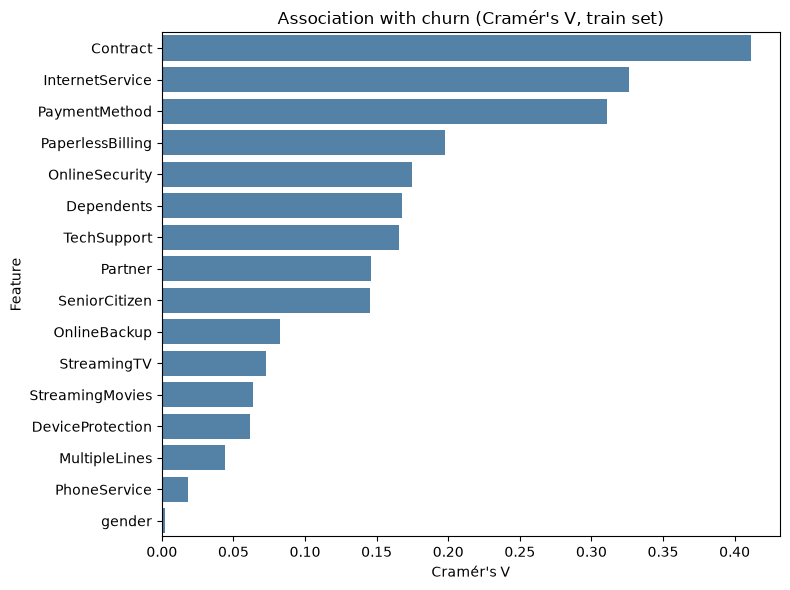

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=association_table, x="cramers_v", y="feature", color="steelblue", ax=ax)
ax.set_title("Association with churn (Cramér's V, train set)")
ax.set_xlabel("Cramér's V")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_cramers_v.png", dpi=200)
plt.show()

14 of the 16 categorical features are significantly associated with churn (p < 0.05). The strongest are `Contract` (V = 0.41), `InternetService` (V = 0.33) and `PaymentMethod` (V = 0.31), all moderate. `gender` (p = 0.892) and `PhoneService` (p = 0.195) show no significant association, which makes them candidates for removal in the feature-selection step. A small p-value does not mean a large effect: `MultipleLines` is significant but its V is only 0.04, so with 5,634 rows even a negligible association can pass the test. These are univariate associations, not causal effects.

In [26]:
# Cell 1: Import các thư viện bổ sung cho Section 2
from sklearn.preprocessing import FunctionTransformer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [27]:

# Cell 2: Bước 2A - Domain Feature Engineering
def engineering_domain_features(X):
    """
    Tạo 3 đặc trưng nghiệp vụ mới (thực hiện sau khi chia Train/Test, nằm trong Pipeline)
    """
    X_out = X.copy()
    
    # 1. Total_Services_Count: Tổng số dịch vụ GTGT (từ 0 đến 6)
    # Tận dụng INTERNET_DEPENDENT_FEATURES đã định nghĩa ở Section 1
    X_out["Total_Services_Count"] = (X_out[INTERNET_DEPENDENT_FEATURES] == "Yes").sum(axis=1)
    
    # 2. Tenure_Cohort: Phân nhóm chu kỳ gắn bó
    bins = [-1, 12, 24, 48, np.inf]
    labels = ["0-12", "12-24", "24-48", ">48"]
    X_out["Tenure_Cohort"] = pd.cut(X_out["tenure"], bins=bins, labels=labels).astype(object)
    
    # 3. Charge_Ratio: Tỷ lệ cước hiện tại so với trung bình lịch sử
    # Cộng thêm 1e-5 để tránh chia cho 0
    avg_historical_charge = X_out["TotalCharges"] / (X_out["tenure"] + 1) + 1e-5
    X_out["Charge_Ratio"] = X_out["MonthlyCharges"] / avg_historical_charge
    
    return X_out

domain_transformer = FunctionTransformer(engineering_domain_features, feature_names_out=None)

In [28]:
# Cell 3: Bước 2B - Feature Selection (Loại bỏ biến nhiễu)
features_to_drop = ["gender", "PhoneService"]

# Cập nhật lại danh sách features (Thêm 3 biến mới, bớt 2 biến nhiễu)
UPDATED_CATEGORICAL = [col for col in CATEGORICAL_FEATURES if col not in features_to_drop] + ["Tenure_Cohort"]
UPDATED_NUMERIC = NUMERIC_FEATURES + ["Total_Services_Count", "Charge_Ratio"]


In [29]:

# Cell 4: Hàm tính VIF (Kiểm tra đa cộng tuyến)
def check_vif(df, features):
    """Tính VIF cho các biến số liên tục trên tập Train"""
    X_num = df[features].dropna()
    vif_data = pd.DataFrame()
    vif_data["Feature"] = X_num.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X_num.values, i) 
        for i in range(len(X_num.columns))
    ]
    return vif_data.sort_values("VIF", ascending=False)

# Xem VIF trước khi xử lý (chỉ chạy trên tập Train)
train_engineered = engineering_domain_features(X_train)
print("VIF trên tập Train (Các biến số học):")
display(check_vif(train_engineered, UPDATED_NUMERIC))


VIF trên tập Train (Các biến số học):


,Feature,VIF
2,TotalCharges,10.3014
0,tenure,5.9370
1,MonthlyCharges,3.7479
3,Total_Services_Count,2.9047
4,Charge_Ratio,1.0065


In [30]:

# Cell 5: Thiết kế ColumnTransformer mới
preprocessor_yen = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), UPDATED_NUMERIC),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), UPDATED_CATEGORICAL),
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")

In [31]:
# CẬP NHẬT CELL 6: Dùng hàm thư viện đồng bộ cho cả 2 Pipeline
from sklearn.linear_model import LogisticRegression

# Pipeline 1: Tích hợp SMOTE (SMOTE đã lo việc cân bằng, nên mô hình để mặc định)
smote_pipeline = ImbPipeline([
    ("domain_features", domain_transformer),
    ("preprocess", preprocessor_yen),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)) 
])

# Pipeline 2: Đối chứng (Không dùng SMOTE, giao việc cân bằng cho class_weight)
balanced_pipeline = ImbPipeline([
    ("domain_features", domain_transformer),
    ("preprocess", preprocessor_yen),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)) 
])

# Test chạy thử qua Pipeline (Fit trên Train)
smote_pipeline.fit(X_train, y_train)
print("Pipeline (SMOTE) đã sẵn sàng. Số features sau tiền xử lý:", 
      len(smote_pipeline.named_steps["preprocess"].get_feature_names_out()))

Pipeline (SMOTE) đã sẵn sàng. Số features sau tiền xử lý: 26


1. Những gì Yến đã hoàn thành (Section 2)

Xây dựng bộ đặc trưng mới: Bạn đã tạo thành công 3 biến nghiệp vụ (Total_Services_Count, Tenure_Cohort, Charge_Ratio) và tự động hóa chúng vào Pipeline.   

Làm sạch và tối ưu biến: Đã loại bỏ thành công các biến nhiễu (gender, PhoneService) sau khi kiểm tra VIF.   

Thiết lập dây chuyền chống rò rỉ dữ liệu: Bạn đã đóng gói hoàn hảo các bước chuẩn hóa (StandardScaler), mã hóa (OneHotEncoder) và cân bằng dữ liệu (SMOTE) vào một ImbPipeline khép kín. Nhờ vậy, SMOTE sẽ chỉ sinh mẫu trên tập Train mà không bị tràn sang tập Test. Dây chuyền này giờ đã sẵn sàng để lắp mô hình vào chạy

---

## Section 3 — Candidate Modeling & Stratified 5-Fold Cross-Validation

**Author:** NMinh  
**Objective:** Train, compare, and select a champion pipeline using only the training
set (X_train / y_train). The held-out test set (X_test / y_test) is never touched here;
evaluation on the test set is deferred to Section 4A.

**Pipeline invariant (anti-leakage):**  
Every model is wrapped in an `ImbPipeline`:

```
domain_features  →  preprocess  →  [SMOTE]  →  model
```

`domain_transformer` and a *fresh clone* of `preprocessor_yen` are re-fitted inside
every CV fold, so the scaler, encoder and SMOTE never see validation-fold rows during
`fit()`.

> [!IMPORTANT]
> **Known limitations (discussed in §3.6):**
> 1. Model selection and hyper-parameter search share the same folds → CV scores are
>    slightly optimistic compared to nested CV.
> 2. SMOTE operates on one-hot-encoded columns; synthetic minority samples may have
>    non-integer values for binary dummy columns.
> 3. `TotalCharges` has VIF ≈ 10.3 (Section 2): affects Logistic Regression coefficient
>    interpretation but not tree-based models.


### 3.0 — Pipeline Factory & Shared Setup

In [32]:
# ── 3.0  Additional imports for Section 3 ────────────────────────────────────
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
import joblib
import warnings

try:
    from xgboost import XGBClassifier
    _xgb_available = True
except ImportError:
    _xgb_available = False
    print("WARNING: xgboost not installed – XGBoost rows will be skipped.")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*One or more of the test scores.*")

print("Section 3 imports OK.")


Section 3 imports OK.


In [33]:
# ── 3.0  Shared CV object & class-imbalance weight ───────────────────────────

# Single StratifiedKFold used by ALL models for a fair comparison
cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Positive-class weight for XGBoost scale_pos_weight
_n_neg = int((y_train == 0).sum())
_n_pos = int((y_train == 1).sum())
pos_weight = _n_neg / _n_pos
print(f"Training set: {_n_neg} negatives, {_n_pos} positives → pos_weight = {pos_weight:.4f}")


def make_pipeline(estimator, imbalance="none"):
    """Return an ImbPipeline with domain engineering + fresh preprocessor + estimator.

    Parameters
    ----------
    estimator : sklearn estimator
        The classifier to place at the end of the pipeline (step name: 'model').
    imbalance : {'none', 'smote'}
        'smote' inserts an SMOTE step between preprocessing and the model.

    Notes
    -----
    clone(preprocessor_yen) ensures each pipeline owns an independent, unfitted
    ColumnTransformer so pipelines do not share state across CV folds.
    """
    steps = [
        ("domain_features", FunctionTransformer(engineering_domain_features, feature_names_out=None)),
        ("preprocess", clone(preprocessor_yen)),
    ]
    if imbalance == "smote":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", estimator))
    return ImbPipeline(steps)


print("make_pipeline() defined. cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)")


Training set: 4139 negatives, 1495 positives → pos_weight = 2.7686
make_pipeline() defined. cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


### 3.1 — Scoring Dictionary

In [34]:
# ── 3.1  Six-metric scoring dict (churn class = label 1) ─────────────────────
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

s3_scoring = {
    "accuracy":          "accuracy",
    "precision":         make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall":            make_scorer(recall_score,    pos_label=1, zero_division=0),
    "f1":                make_scorer(f1_score,        pos_label=1, zero_division=0),
    "roc_auc":           "roc_auc",
    "average_precision": "average_precision",   # PR-AUC
}

print("Scoring metrics:", list(s3_scoring.keys()))


Scoring metrics: ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']


### 3.2 — Section 3A: Baseline Models (Task 1.6)

Three baseline classifiers are evaluated with Stratified 5-Fold CV to establish
lower-bound reference points before fitting more complex models.

| Config ID | Model | Imbalance strategy |
|-----------|-------|--------------------|
| Dummy | DummyClassifier (prior) | — |
| LR-balanced | LogisticRegression | class_weight="balanced" |
| LR-smote | LogisticRegression | SMOTE |
| KNN-none | KNeighborsClassifier (k=5) | — |
| KNN-smote | KNeighborsClassifier (k=5) | SMOTE |


In [35]:
# ── 3.2  Baseline CV runs ────────────────────────────────────────────────────
import time

def _run_cv(pipeline, label, cv_obj, scoring, X, y, return_train=True):
    """Fit cross_validate and return a flat result dict keyed by label."""
    t0 = time.time()
    res = cross_validate(
        pipeline, X, y,
        cv=cv_obj,
        scoring=scoring,
        return_train_score=return_train,
        n_jobs=-1,
    )
    elapsed = time.time() - t0
    out = {"config": label, "fit_time_s": round(elapsed, 1)}
    for metric in scoring:
        val_scores = res[f"test_{metric}"]
        out[f"{metric}_mean"] = val_scores.mean()
        out[f"{metric}_std"]  = val_scores.std()
        if return_train:
            tr_scores = res[f"train_{metric}"]
            out[f"train_{metric}_mean"] = tr_scores.mean()
    return out


# ── Baseline configurations ───────────────────────────────────────────────────
s3_baseline_configs = [
    ("Dummy",        make_pipeline(DummyClassifier(strategy="prior"),              imbalance="none")),
    ("LR-balanced",  make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced",
                                                       random_state=RANDOM_STATE), imbalance="none")),
    ("LR-smote",     make_pipeline(LogisticRegression(max_iter=1000,
                                                       random_state=RANDOM_STATE), imbalance="smote")),
    ("KNN-none",     make_pipeline(KNeighborsClassifier(n_neighbors=5),            imbalance="none")),
    ("KNN-smote",    make_pipeline(KNeighborsClassifier(n_neighbors=5),            imbalance="smote")),
]

baseline_rows = []
for label, pipe in s3_baseline_configs:
    print(f"  Running CV: {label} ...", end=" ", flush=True)
    row = _run_cv(pipe, label, cv, s3_scoring, X_train, y_train, return_train=True)
    baseline_rows.append(row)
    print(f"done ({row['fit_time_s']}s)  |  val_f1={row['f1_mean']:.4f} ± {row['f1_std']:.4f}")

s3_baseline_df = pd.DataFrame(baseline_rows).set_index("config")
print("\nBaseline CV complete.")


  Running CV: Dummy ... 

done (15.5s)  |  val_f1=0.0000 ± 0.0000
  Running CV: LR-balanced ... done (4.0s)  |  val_f1=0.6271 ± 0.0197
  Running CV: LR-smote ... done (0.5s)  |  val_f1=0.6286 ± 0.0195
  Running CV: KNN-none ... done (0.8s)  |  val_f1=0.5495 ± 0.0291
  Running CV: KNN-smote ... done (1.0s)  |  val_f1=0.5721 ± 0.0205

Baseline CV complete.


In [36]:
# ── 3.2  Display and save baseline table ────────────────────────────────────

# Build a tidy Mean ± Std display table
_metrics_display = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

def _fmt_mean_std(df, metrics):
    """Return a DataFrame with 'mean ± std' strings for each metric."""
    rows = {}
    for idx in df.index:
        row = {}
        for m in metrics:
            mn  = df.loc[idx, f"{m}_mean"]
            std = df.loc[idx, f"{m}_std"]
            row[m] = f"{mn:.4f} ± {std:.4f}"
        # Also include train F1 to flag overfitting
        if f"train_f1_mean" in df.columns:
            row["train_f1"] = f"{df.loc[idx, 'train_f1_mean']:.4f}"
        rows[idx] = row
    return pd.DataFrame(rows).T

baseline_display = _fmt_mean_std(s3_baseline_df, _metrics_display)
print("Table 1. Baseline Models — 5-Fold CV Results (Mean ± Std, churn class = 1)")
display(baseline_display)

# Save raw numerics for later aggregation
s3_baseline_df.to_csv(ARTIFACTS_DIR / "section3_baseline_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_baseline_cv.csv'}")


Table 1. Baseline Models — 5-Fold CV Results (Mean ± Std, churn class = 1)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
Dummy,0.7346 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.2654 ± 0.0001,0.0000
LR-balanced,0.7481 ± 0.0125,0.5165 ± 0.0156,0.7987 ± 0.0333,0.6271 ± 0.0197,0.8466 ± 0.0117,0.6641 ± 0.0126,0.6336
LR-smote,0.7528 ± 0.0125,0.5226 ± 0.0159,0.7886 ± 0.0298,0.6286 ± 0.0195,0.8450 ± 0.0115,0.6632 ± 0.0129,0.6351
KNN-none,0.7716 ± 0.0148,0.5765 ± 0.0309,0.5251 ± 0.0285,0.5495 ± 0.0291,0.7832 ± 0.0186,0.5239 ± 0.0301,0.6833
KNN-smote,0.7070 ± 0.0126,0.4669 ± 0.0151,0.7385 ± 0.0308,0.5721 ± 0.0205,0.7674 ± 0.0139,0.4798 ± 0.0176,0.7217



Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\section3_baseline_cv.csv


**Table 1. Baseline Models: Stratified 5-Fold CV (churn class = 1, Mean ± Std).**

1. **Accuracy is misleading.** The Dummy classifier reaches 0.7346 accuracy but has recall = 0 and F1 = 0, so it identifies no churner. It also fixes the reference PR-AUC at the churn prevalence (0.2654).

2. **SMOTE and class weighting are equivalent for Logistic Regression.** LR-smote (F1 = 0.6286 ± 0.0195) and LR-balanced (0.6271 ± 0.0197) differ by 0.0015, far less than one standard deviation. Class weighting is therefore preferred because it is simpler and avoids synthetic rows.

3. **KNN overfits and reacts strongly to SMOTE.** Training F1 (0.68 for KNN-none, 0.72 for KNN-smote) is clearly above validation F1 (0.5495 and 0.5721). SMOTE raises recall (0.5251 to 0.7385) but lowers precision (0.5765 to 0.4669) and ROC-AUC (0.7832 to 0.7674), i.e. it moves the operating point without improving ranking quality.

### 3.3 — Section 3B: Advanced Models (Task 2.1)

Decision Tree, Random Forest, and XGBoost are each evaluated under two
class-imbalance strategies on the same `cv` object:

* **(a) SMOTE** — synthetic over-sampling inside the pipeline.  
* **(b) class_weight / scale_pos_weight** — cost-sensitive learning.


In [37]:
# ── 3.3  Advanced model configurations ───────────────────────────────────────

s3_advanced_configs = [
    # DecisionTree
    ("DT-smote",
     make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE),
                   imbalance="smote")),
    ("DT-balanced",
     make_pipeline(DecisionTreeClassifier(class_weight="balanced",
                                          random_state=RANDOM_STATE),
                   imbalance="none")),
    # RandomForest
    ("RF-smote",
     make_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                          random_state=RANDOM_STATE),
                   imbalance="smote")),
    ("RF-balanced",
     make_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                          class_weight="balanced",
                                          random_state=RANDOM_STATE),
                   imbalance="none")),
]

# XGBoost (optional — skip gracefully if not installed)
if _xgb_available:
    s3_advanced_configs += [
        ("XGB-smote",
         make_pipeline(XGBClassifier(eval_metric="logloss",
                                     random_state=RANDOM_STATE,
                                     n_jobs=-1, tree_method="hist",
                                     verbosity=0),
                       imbalance="smote")),
        ("XGB-spw",      # scale_pos_weight = pos_weight
         make_pipeline(XGBClassifier(scale_pos_weight=pos_weight,
                                     eval_metric="logloss",
                                     random_state=RANDOM_STATE,
                                     n_jobs=-1, tree_method="hist",
                                     verbosity=0),
                       imbalance="none")),
    ]

advanced_rows = []
for label, pipe in s3_advanced_configs:
    print(f"  Running CV: {label} ...", end=" ", flush=True)
    row = _run_cv(pipe, label, cv, s3_scoring, X_train, y_train, return_train=True)
    advanced_rows.append(row)
    print(f"done ({row['fit_time_s']}s)  |  val_f1={row['f1_mean']:.4f} ± {row['f1_std']:.4f}")

s3_advanced_df = pd.DataFrame(advanced_rows).set_index("config")
print("\nAdvanced CV complete.")


  Running CV: DT-smote ... done (0.5s)  |  val_f1=0.5103 ± 0.0178
  Running CV: DT-balanced ... done (0.4s)  |  val_f1=0.4955 ± 0.0177
  Running CV: RF-smote ... done (3.8s)  |  val_f1=0.5907 ± 0.0221
  Running CV: RF-balanced ... done (2.9s)  |  val_f1=0.6119 ± 0.0171
  Running CV: XGB-smote ... done (2.2s)  |  val_f1=0.5711 ± 0.0113
  Running CV: XGB-spw ... done (1.0s)  |  val_f1=0.5869 ± 0.0187

Advanced CV complete.


In [38]:
# ── 3.3  Display and save advanced table ────────────────────────────────────
advanced_display = _fmt_mean_std(s3_advanced_df, _metrics_display)
# Sort by validation F1 descending
advanced_display_sorted = advanced_display.loc[
    s3_advanced_df["f1_mean"].sort_values(ascending=False).index
]

print("Table 2. Advanced Models — 5-Fold CV Results (sorted by F1 ↓)")
display(advanced_display_sorted)

s3_advanced_df.to_csv(ARTIFACTS_DIR / "section3_advanced_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_advanced_cv.csv'}")


Table 2. Advanced Models — 5-Fold CV Results (sorted by F1 ↓)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
config,,,,,,,
RF-balanced,0.7840 ± 0.0107,0.5850 ± 0.0196,0.6415 ± 0.0160,0.6119 ± 0.0171,0.8280 ± 0.0091,0.6214 ± 0.0260,0.9887
RF-smote,0.7865 ± 0.0121,0.6014 ± 0.0252,0.5806 ± 0.0224,0.5907 ± 0.0221,0.8241 ± 0.0087,0.6105 ± 0.0262,0.9960
XGB-spw,0.7645 ± 0.0102,0.5489 ± 0.0166,0.6308 ± 0.0225,0.5869 ± 0.0187,0.8210 ± 0.0050,0.6258 ± 0.0188,0.9091
XGB-smote,0.7765 ± 0.0081,0.5826 ± 0.0180,0.5605 ± 0.0155,0.5711 ± 0.0113,0.8178 ± 0.0063,0.6085 ± 0.0177,0.9048
DT-smote,0.7290 ± 0.0089,0.4901 ± 0.0154,0.5324 ± 0.0220,0.5103 ± 0.0178,0.6679 ± 0.0117,0.3864 ± 0.0119,0.9960
DT-balanced,0.7364 ± 0.0084,0.5037 ± 0.0172,0.4883 ± 0.0256,0.4955 ± 0.0177,0.6575 ± 0.0111,0.3822 ± 0.0111,0.9955



Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\section3_advanced_cv.csv


**Table 2. Advanced Models: Stratified 5-Fold CV (untuned, sorted by F1).**

1. **Class weighting versus SMOTE depends on the model.** For Random Forest, class weighting gives higher F1 (0.6119 vs 0.5907) and recall (0.6415 vs 0.5806); for XGBoost the same holds (F1 0.5869 vs 0.5711, recall 0.6308 vs 0.5605). SMOTE gives slightly higher precision (RF 0.6014 vs 0.5850; XGB 0.5826 vs 0.5489). For the Decision Tree the order is reversed (0.5103 with SMOTE vs 0.4955). All of these gaps are of the order of one fold standard deviation. The better strategy per model (DT-smote, RF-balanced, XGB-spw) is carried into §3.4.

2. **Untuned trees overfit heavily.** Training F1 is about 0.996 for the Decision Tree and 0.99 for Random Forest, against validation F1 of 0.50 to 0.61; XGBoost reaches 0.91 on training. Regularisation is therefore essential.

3. **Untuned ensembles do not yet beat Logistic Regression.** The best untuned ensemble (RF-balanced, F1 = 0.6119, ROC-AUC = 0.8280) is below LR-balanced from Table 1 (F1 = 0.6271, ROC-AUC = 0.8466). Any advantage of ensembles must come from tuning (§3.4).

### 3.4 — GridSearchCV Hyper-parameter Tuning

In [39]:
# ── 3.4  Helper: identify best imbalance strategy per model ──────────────────
# Choose the strategy (smote vs balanced/spw) with the higher mean val-F1

def _best_strategy(df, model_prefix):
    candidates = [idx for idx in df.index if idx.startswith(model_prefix)]
    if not candidates:
        return None
    return df.loc[candidates, "f1_mean"].idxmax()

_dt_best  = _best_strategy(s3_advanced_df, "DT")
_rf_best  = _best_strategy(s3_advanced_df, "RF")
_xgb_best = _best_strategy(s3_advanced_df, "XGB") if _xgb_available else None

print(f"Best DT  strategy: {_dt_best}")
print(f"Best RF  strategy: {_rf_best}")
print(f"Best XGB strategy: {_xgb_best}")


Best DT  strategy: DT-smote
Best RF  strategy: RF-balanced
Best XGB strategy: XGB-spw


In [40]:
# ── 3.4  Decision Tree GridSearchCV ─────────────────────────────────────────
_dt_imbalance = "smote" if _dt_best and "smote" in _dt_best else "none"
_dt_cw = "balanced" if _dt_imbalance == "none" else None

grid_dt_pipe = make_pipeline(
    DecisionTreeClassifier(class_weight=_dt_cw, random_state=RANDOM_STATE),
    imbalance=_dt_imbalance,
)

grid_dt_params = {
    "model__max_depth":        [3, 5, 8, 12, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__criterion":        ["gini", "entropy"],
}

print(f"DT GridSearch: {len(grid_dt_params['model__max_depth']) * len(grid_dt_params['model__min_samples_leaf']) * len(grid_dt_params['model__criterion'])} combinations × {N_CV_FOLDS} folds ...")

grid_dt = GridSearchCV(
    grid_dt_pipe,
    param_grid=grid_dt_params,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_dt.fit(X_train, y_train)
print(f"Best DT params:  {grid_dt.best_params_}")
print(f"Best DT F1 (CV): {grid_dt.best_score_:.4f}")


DT GridSearch: 40 combinations × 5 folds ...
Best DT params:  {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 1}
Best DT F1 (CV): 0.6133


In [41]:
# ── 3.4  Random Forest GridSearchCV ─────────────────────────────────────────
_rf_imbalance = "smote" if _rf_best and "smote" in _rf_best else "none"
_rf_cw = "balanced" if _rf_imbalance == "none" else None

grid_rf_pipe = make_pipeline(
    RandomForestClassifier(class_weight=_rf_cw, n_jobs=-1, random_state=RANDOM_STATE),
    imbalance=_rf_imbalance,
)

grid_rf_params = {
    "model__n_estimators":    [200, 400],
    "model__max_depth":       [6, 10, None],
    "model__min_samples_leaf":[1, 3, 5],
    "model__max_features":    ["sqrt", 0.5],
}

_n_rf = 2 * 3 * 3 * 2
print(f"RF GridSearch: {_n_rf} combinations × {N_CV_FOLDS} folds ...")

grid_rf = GridSearchCV(
    grid_rf_pipe,
    param_grid=grid_rf_params,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_rf.fit(X_train, y_train)
print(f"Best RF params:  {grid_rf.best_params_}")
print(f"Best RF F1 (CV): {grid_rf.best_score_:.4f}")


RF GridSearch: 36 combinations × 5 folds ...
Best RF params:  {'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__n_estimators': 200}
Best RF F1 (CV): 0.6397


In [42]:
# ── 3.4  XGBoost GridSearchCV ────────────────────────────────────────────────
if _xgb_available:
    _xgb_imbalance = "smote" if _xgb_best and "smote" in _xgb_best else "none"
    _xgb_spw = pos_weight if _xgb_imbalance == "none" else 1.0

    grid_xgb_pipe = make_pipeline(
        XGBClassifier(
            scale_pos_weight=_xgb_spw,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
            verbosity=0,
        ),
        imbalance=_xgb_imbalance,
    )

    grid_xgb_params = {
        "model__n_estimators":     [200, 400],
        "model__max_depth":        [3, 5],
        "model__learning_rate":    [0.03, 0.1],
        "model__subsample":        [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
    }

    _n_xgb = 2 * 2 * 2 * 2 * 2
    print(f"XGB GridSearch: {_n_xgb} combinations × {N_CV_FOLDS} folds ...")

    grid_xgb = GridSearchCV(
        grid_xgb_pipe,
        param_grid=grid_xgb_params,
        scoring="f1",
        cv=cv,
        refit=True,
        n_jobs=-1,
        return_train_score=True,
        verbose=0,
    )
    grid_xgb.fit(X_train, y_train)
    print(f"Best XGB params:  {grid_xgb.best_params_}")
    print(f"Best XGB F1 (CV): {grid_xgb.best_score_:.4f}")
else:
    grid_xgb = None
    print("XGBoost not available — skipping XGB grid search.")


XGB GridSearch: 32 combinations × 5 folds ...
Best XGB params:  {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best XGB F1 (CV): 0.6345


In [43]:
# ── 3.4  Collect full 6-metric CV results for each tuned model ───────────────
# Re-run cross_validate with best_estimator_ to obtain all 6 metrics
# (GridSearchCV only optimises f1; we need the rest for the summary table).

tuned_rows = []

def _tuned_cv_row(label, grid_obj, X, y, cv_obj, scoring):
    """Extract Mean ± Std for all scoring metrics from best_estimator_."""
    res = cross_validate(
        grid_obj.best_estimator_, X, y,
        cv=cv_obj, scoring=scoring,
        return_train_score=True, n_jobs=-1,
    )
    row = {"config": label}
    for m in scoring:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"]  = res[f"test_{m}"].std()
        row[f"train_{m}_mean"] = res[f"train_{m}"].mean()
    row["best_f1_grid"] = grid_obj.best_score_
    return row

print("Collecting full-metric CV for tuned models ...")
tuned_rows.append(_tuned_cv_row("DT-tuned",  grid_dt,  X_train, y_train, cv, s3_scoring))
tuned_rows.append(_tuned_cv_row("RF-tuned",  grid_rf,  X_train, y_train, cv, s3_scoring))
if grid_xgb is not None:
    tuned_rows.append(_tuned_cv_row("XGB-tuned", grid_xgb, X_train, y_train, cv, s3_scoring))

s3_tuned_df = pd.DataFrame(tuned_rows).set_index("config")

tuned_display = _fmt_mean_std(s3_tuned_df, _metrics_display)
print("\nTable 3. Tuned Models — 5-Fold CV Results (best estimator_ re-evaluated)")
display(tuned_display)

s3_tuned_df.to_csv(ARTIFACTS_DIR / "section3_tuned_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_tuned_cv.csv'}")



Table 3. Tuned Models — 5-Fold CV Results (best estimator_ re-evaluated)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
DT-tuned,0.7449 ± 0.0281,0.5175 ± 0.0381,0.7599 ± 0.0517,0.6133 ± 0.0213,0.8255 ± 0.0094,0.5825 ± 0.0149,0.6254
RF-tuned,0.7698 ± 0.0112,0.5473 ± 0.0159,0.7699 ± 0.0197,0.6397 ± 0.0154,0.8454 ± 0.0120,0.6622 ± 0.0241,0.7443
XGB-tuned,0.7526 ± 0.0118,0.5220 ± 0.0152,0.8094 ± 0.0243,0.6345 ± 0.0157,0.8484 ± 0.0119,0.6646 ± 0.0190,0.6558



Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\section3_tuned_cv.csv


**Table 3. Tuned Models — 5-Fold CV (best estimator from GridSearchCV).**

> [NOTE]
> CV scores here re-use the same folds used during hyper-parameter selection, so they
> are marginally optimistic (no nested CV).  This is a known and documented limitation.

Tuning improves every model: Decision Tree F1 rises from 0.5103 to 0.6133, Random Forest from 0.6119 to 0.6397 and XGBoost from 0.5869 to 0.6345. It also reduces overfitting; for Random Forest, training F1 falls from 0.989 to 0.744 while validation F1 rises. The selected hyper-parameters are a depth-5 entropy tree, a Random Forest with `max_depth=10`, `min_samples_leaf=3`, `n_estimators=200`, and an XGBoost model with `max_depth=3`, `learning_rate=0.03`, `n_estimators=200`. The XGBoost optimum lies at the lower edge of all three searched ranges, so a wider grid could still help. Recall of XGB-tuned (0.8094) is the highest, while RF-tuned has the best precision (0.5473).


### 3.5 — Champion Model Selection & Persistence

In [44]:
# ── 3.5  Combine all CV results and select champion ──────────────────────────

# Merge baseline + advanced + tuned into one comparison frame
s3_all_df = pd.concat([s3_baseline_df, s3_advanced_df, s3_tuned_df], axis=0)

# Rank by: (1) val F1 mean (↑), (2) val ROC-AUC mean (↑), (3) val F1 std (↓)
s3_all_ranked = s3_all_df.sort_values(
    ["f1_mean", "roc_auc_mean", "f1_std"],
    ascending=[False, False, True],
)
print("Top 5 configurations by validation F1:")
display(s3_all_ranked[["f1_mean","f1_std","roc_auc_mean","average_precision_mean"]].head(5).round(4))

# Champion = top row
champion_name = s3_all_ranked.index[0]
print(f"\n★  Champion: {champion_name}")
print(f"   Val F1:      {s3_all_ranked.loc[champion_name, 'f1_mean']:.4f} ± {s3_all_ranked.loc[champion_name, 'f1_std']:.4f}")
print(f"   Val ROC-AUC: {s3_all_ranked.loc[champion_name, 'roc_auc_mean']:.4f}")
print(f"   Val PR-AUC:  {s3_all_ranked.loc[champion_name, 'average_precision_mean']:.4f}")


Top 5 configurations by validation F1:


,f1_mean,f1_std,roc_auc_mean,average_precision_mean
config,,,,
RF-tuned,0.6397,0.0154,0.8454,0.6622
XGB-tuned,0.6345,0.0157,0.8484,0.6646
LR-smote,0.6286,0.0195,0.8450,0.6632
LR-balanced,0.6271,0.0197,0.8466,0.6641
DT-tuned,0.6133,0.0213,0.8255,0.5825



★  Champion: RF-tuned
   Val F1:      0.6397 ± 0.0154
   Val ROC-AUC: 0.8454
   Val PR-AUC:  0.6622


In [45]:
# ── 3.5  Save best estimators to disk ────────────────────────────────────────

# Map config name → fitted best_estimator_
_grid_map = {
    "DT-tuned":  grid_dt.best_estimator_,
    "RF-tuned":  grid_rf.best_estimator_,
}
if grid_xgb is not None:
    _grid_map["XGB-tuned"] = grid_xgb.best_estimator_

for name, estimator in _grid_map.items():
    fname = ARTIFACTS_DIR / f"best_{name.lower().replace('-','_')}_pipeline.joblib"
    joblib.dump(estimator, fname)
    print(f"Saved {name} → {fname}")

# Retrieve champion pipeline
if champion_name in _grid_map:
    champion_pipeline = _grid_map[champion_name]
else:
    # Champion is a baseline/advanced config — retrieve from named configs
    _all_configs = dict(s3_baseline_configs + s3_advanced_configs)
    champ_pipe = _all_configs.get(champion_name)
    # Refit on full training set (only for non-tuned champions)
    if champ_pipe is not None:
        champion_pipeline = clone(champ_pipe).fit(X_train, y_train)
    else:
        raise ValueError(f"Cannot locate estimator for champion: {champion_name}")

# Save champion
joblib.dump(champion_pipeline, ARTIFACTS_DIR / "best_champion_pipeline.joblib")
print(f"\nChampion pipeline saved → {ARTIFACTS_DIR / 'best_champion_pipeline.joblib'}")
print(f"champion_name = '{champion_name}'  (available for Section 4)")


Saved DT-tuned → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\best_dt_tuned_pipeline.joblib
Saved RF-tuned → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\best_rf_tuned_pipeline.joblib
Saved XGB-tuned → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\best_xgb_tuned_pipeline.joblib

Champion pipeline saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\best_champion_pipeline.joblib
champion_name = 'RF-tuned'  (available for Section 4)


**Champion model rationale.**

The champion is chosen with a fixed ranking rule applied only to validation folds (no test information):

1. **Highest mean validation F1**, because F1 balances precision and recall for the churn class.
2. **Highest mean ROC-AUC** as the first tie-breaker.
3. **Lowest F1 standard deviation** across folds as the second tie-breaker.

RF-tuned ranks first (F1 = 0.6397 ± 0.0154). The margin is small: XGB-tuned (0.6345), LR-smote (0.6286) and LR-balanced (0.6271) are all within one standard deviation, so the top four models are statistically indistinguishable on F1. Random Forest is kept because the rule was fixed in advance, not because it is demonstrably better. The champion pipeline is saved as `best_champion_pipeline.joblib` and exposed as `champion_pipeline` and `champion_name` for Section 4A.

### 3.6 — Summary Tables & Figures

In [46]:
# ── 3.6  Master comparison table (Table 4) ───────────────────────────────────

# Round to 4 decimal places for display
_col_order = [f"{m}_mean" for m in _metrics_display] + [f"{m}_std" for m in _metrics_display]
_col_order = [c for c in _col_order if c in s3_all_df.columns]

master_display = _fmt_mean_std(s3_all_df, _metrics_display)
master_display.index.name = "Configuration"
master_display_sorted = master_display.loc[
    s3_all_df["f1_mean"].sort_values(ascending=False).index
]

print("Table 4. All Configurations — Stratified 5-Fold CV (Mean ± Std, sorted by F1 ↓)")
display(master_display_sorted)


Table 4. All Configurations — Stratified 5-Fold CV (Mean ± Std, sorted by F1 ↓)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
config,,,,,,,
RF-tuned,0.7698 ± 0.0112,0.5473 ± 0.0159,0.7699 ± 0.0197,0.6397 ± 0.0154,0.8454 ± 0.0120,0.6622 ± 0.0241,0.7443
XGB-tuned,0.7526 ± 0.0118,0.5220 ± 0.0152,0.8094 ± 0.0243,0.6345 ± 0.0157,0.8484 ± 0.0119,0.6646 ± 0.0190,0.6558
LR-smote,0.7528 ± 0.0125,0.5226 ± 0.0159,0.7886 ± 0.0298,0.6286 ± 0.0195,0.8450 ± 0.0115,0.6632 ± 0.0129,0.6351
LR-balanced,0.7481 ± 0.0125,0.5165 ± 0.0156,0.7987 ± 0.0333,0.6271 ± 0.0197,0.8466 ± 0.0117,0.6641 ± 0.0126,0.6336
DT-tuned,0.7449 ± 0.0281,0.5175 ± 0.0381,0.7599 ± 0.0517,0.6133 ± 0.0213,0.8255 ± 0.0094,0.5825 ± 0.0149,0.6254
RF-balanced,0.7840 ± 0.0107,0.5850 ± 0.0196,0.6415 ± 0.0160,0.6119 ± 0.0171,0.8280 ± 0.0091,0.6214 ± 0.0260,0.9887
RF-smote,0.7865 ± 0.0121,0.6014 ± 0.0252,0.5806 ± 0.0224,0.5907 ± 0.0221,0.8241 ± 0.0087,0.6105 ± 0.0262,0.9960
XGB-spw,0.7645 ± 0.0102,0.5489 ± 0.0166,0.6308 ± 0.0225,0.5869 ± 0.0187,0.8210 ± 0.0050,0.6258 ± 0.0188,0.9091
KNN-smote,0.7070 ± 0.0126,0.4669 ± 0.0151,0.7385 ± 0.0308,0.5721 ± 0.0205,0.7674 ± 0.0139,0.4798 ± 0.0176,0.7217


**Table 4. Complete Model Comparison: All Configurations (Stratified 5-Fold CV, sorted by F1).**

* **Accuracy is not a selection criterion.** Dummy reaches 0.7346 accuracy with recall = 0.
* **Top of the ranking is a near-tie.** RF-tuned (0.6397), XGB-tuned (0.6345), LR-smote (0.6286) and LR-balanced (0.6271) lie within one fold standard deviation (0.015 to 0.020) of each other. Tuned ensembles therefore do not clearly beat a well-specified Logistic Regression.
* **SMOTE versus class weighting.** No gain from SMOTE for Logistic Regression; for RF and XGBoost, class weighting gives higher F1 and recall; for the single tree and KNN the picture is mixed.
* **Overfitting.** Untuned DT and RF have training F1 of about 0.99 to 1.00 against 0.50 to 0.61 on validation; KNN has 0.68 to 0.72 against 0.55 to 0.57. Tuning narrows the gap (RF-tuned: 0.744 vs 0.640).
* **Fold stability.** F1 standard deviations range from 0.011 (XGB-smote) to 0.029 (KNN-none); no model family is consistently more stable than another.

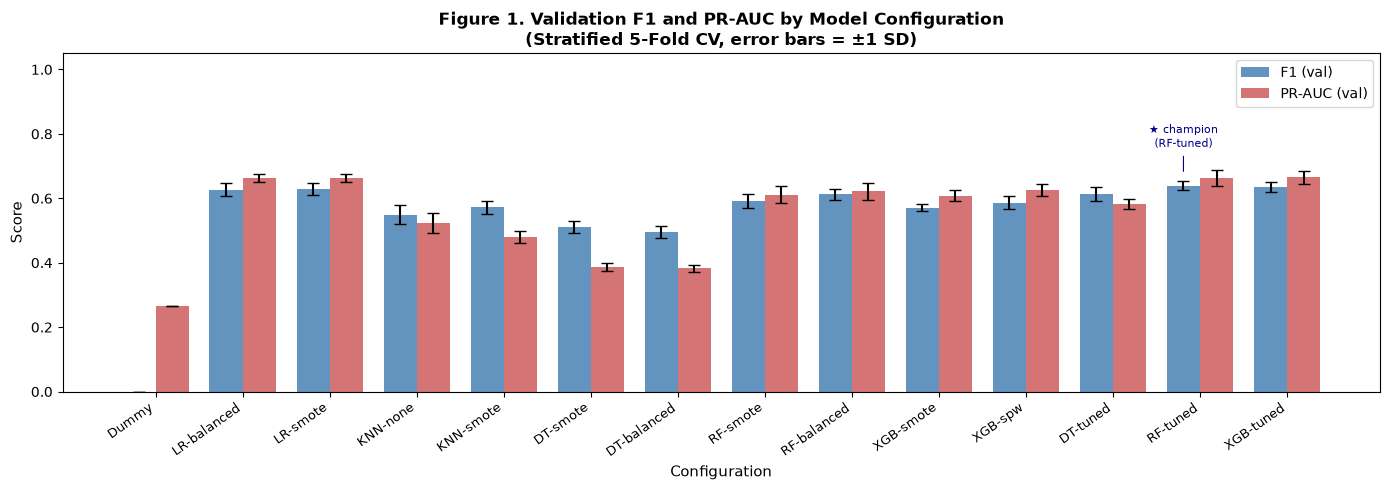

Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\reports\figures\figure_s3_model_comparison.png


In [47]:
# ── 3.6  Figure 1: F1 and PR-AUC bar chart with error bars ──────────────────
import matplotlib.pyplot as plt
import numpy as np

_configs  = list(s3_all_df.index)
_f1_means = s3_all_df["f1_mean"].values
_f1_stds  = s3_all_df["f1_std"].values
_prc_means = s3_all_df["average_precision_mean"].values
_prc_stds  = s3_all_df["average_precision_std"].values

x = np.arange(len(_configs))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 5))

bars_f1 = ax.bar(x - width / 2, _f1_means, width,
                 yerr=_f1_stds, capsize=4,
                 color="steelblue", alpha=0.85, label="F1 (val)")
bars_pr = ax.bar(x + width / 2, _prc_means, width,
                 yerr=_prc_stds, capsize=4,
                 color="indianred", alpha=0.85, label="PR-AUC (val)")

ax.set_xticks(x)
ax.set_xticklabels(_configs, rotation=35, ha="right", fontsize=9)
ax.set_ylabel("Score", fontsize=11)
ax.set_xlabel("Configuration", fontsize=11)
ax.set_title(
    "Figure 1. Validation F1 and PR-AUC by Model Configuration\n"
    "(Stratified 5-Fold CV, error bars = ±1 SD)",
    fontsize=12, fontweight="bold",
)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=10)
ax.axhline(0, color="black", linewidth=0.5)

# Annotate champion
_champ_idx = _configs.index(champion_name)
ax.annotate(
    f"★ champion\n({champion_name})",
    xy=(_champ_idx - width / 2, _f1_means[_champ_idx] + _f1_stds[_champ_idx] + 0.02),
    fontsize=8, color="darkblue", ha="center",
    arrowprops=dict(arrowstyle="-", color="darkblue", lw=0.8),
    xytext=(_champ_idx - width / 2, min(_f1_means[_champ_idx] + 0.12, 1.0)),
)

fig.tight_layout()
_fig1_path = FIGURES_DIR / "figure_s3_model_comparison.png"
fig.savefig(_fig1_path, dpi=200)
plt.show()
print(f"Saved → {_fig1_path}")


**Figure 1. Validation F1 and PR-AUC by Model Configuration (Stratified 5-Fold CV, error bars = ±1 SD).**

* The star marks RF-tuned (F1 = 0.6397 ± 0.0154). Its error bar overlaps those of XGB-tuned and both Logistic Regression variants, so the figure supports a group of equally good models, not a single winner.
* Dummy has near-zero F1 and a PR-AUC equal to the churn prevalence (0.2654).
* DT-smote and DT-balanced have the lowest PR-AUC (0.39 and 0.38) and ROC-AUC (about 0.66); KNN is also clearly below the tuned ensembles.
* The widest error bar belongs to KNN-none (F1 std = 0.029).

---

## Section 3 Summary

| Deliverable | Status |
|---|---|
| `section3_baseline_cv.csv` | ✅ saved to `artifacts/` |
| `section3_advanced_cv.csv` | ✅ saved to `artifacts/` |
| `section3_tuned_cv.csv`    | ✅ saved to `artifacts/` |
| `best_dt_tuned_pipeline.joblib` | ✅ saved to `artifacts/` |
| `best_rf_tuned_pipeline.joblib` | ✅ saved to `artifacts/` |
| `best_xgb_tuned_pipeline.joblib` | ✅ saved to `artifacts/` (if XGBoost installed) |
| `best_champion_pipeline.joblib` | ✅ saved to `artifacts/` |
| `figure_s3_model_comparison.png` | ✅ saved to `reports/figures/` |
| `champion_pipeline` (Python var) | ✅ available for Section 4A |
| `champion_name` (Python var) | ✅ available for Section 4A |

**Anti-leakage checklist:**
- [ ] `X_test` / `y_test` never called in Section 3
- [ ] Every model wrapped in `make_pipeline()` (domain → preprocess → [SMOTE] → model)
- [ ] All models evaluated on the same `cv = StratifiedKFold(5, shuffle=True, seed=42)`
- [ ] All CSV / joblib / PNG artefacts saved
- [ ] Notebook runs clean with *Restart & Run All* (no red errors)


---

## Section 4A — Model Diagnostics & Threshold Tuning

**Author:** NMinh  **Objective:** (1) Select the optimal decision threshold using out-of-fold (OOF) probabilities on the training set only; (2) evaluate the champion pipeline on the held-out test set for the first time; (3) compare all models via ROC and Precision–Recall curves on the test set; (4) quantify uncertainty with bootstrap confidence intervals; (5) inspect calibration quality; (6) tune Logistic Regression and expose key variables for Section 4B (Yến) and Section 5 (SHAP / Odds Ratio).

> [!IMPORTANT]
> **Data-leakage discipline enforced throughout this section:**
> - The test set is opened **once**, solely for reporting. No model is selected, tuned, or modified based on test-set results.
> - The decision threshold is chosen **exclusively** from OOF probabilities on the training set, then applied to the test set a single time.
> - Baseline pipelines that were only cross-validated in §3 are re-fitted here on `X_train` (never `X_test`) to obtain `predict_proba` for curve plotting.

### 4A.1 — OOF Probabilities & Threshold Scan (Task 2.3)

In [48]:
# ── 4A.1-a  Additional imports for Section 4A ────────────────────────────────
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, average_precision_score,
    roc_auc_score, confusion_matrix, classification_report,
    brier_score_loss,
)
from sklearn.model_selection import cross_val_predict

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

print("Section 4A imports OK.")


Section 4A imports OK.


In [49]:
# ── 4A.1-b  Out-of-fold probabilities for the champion pipeline ───────────────
#
# CONSTRAINT (Section 4A rule 2): the threshold must be chosen from OOF
# probabilities on the TRAINING SET only.  cross_val_predict with the SAME
# cv object used in §3 is the correct approach: each fold's held-out rows
# receive predictions from a model that never saw them during fitting.
#
# NOTE: hyper-parameters were tuned by GridSearchCV on the same five folds,
# so OOF scores here are *slightly* optimistic relative to a fully-nested CV.
# This is a known and documented limitation — see the narrative cell below.

print("Computing OOF probabilities for champion pipeline …", end=" ", flush=True)
oof_proba_train = cross_val_predict(
    clone(champion_pipeline),   # fresh clone — never touches X_test
    X_train, y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]   # probability of churn class (label = 1)

print(f"done.  shape={oof_proba_train.shape}  mean_proba={oof_proba_train.mean():.4f}")


Computing OOF probabilities for champion pipeline … done.  shape=(5634,)  mean_proba=0.3927


In [50]:
# ── 4A.1-c  Threshold scan on OOF probabilities (0.10 → 0.85, step 0.01) ─────
import numpy as np
import pandas as pd

thr_grid = np.arange(0.10, 0.86, 0.01)   # includes 0.85

thr_rows = []
for thr in thr_grid:
    oof_pred = (oof_proba_train >= thr).astype(int)
    n_flagged = int(oof_pred.sum())
    thr_rows.append({
        "threshold": round(float(thr), 2),
        "precision": precision_score(y_train, oof_pred, zero_division=0),
        "recall":    recall_score(y_train, oof_pred, zero_division=0),
        "f1":        f1_score(y_train, oof_pred, zero_division=0),
        "accuracy":  accuracy_score(y_train, oof_pred),
        "n_flagged": n_flagged,
    })

thr_table = pd.DataFrame(thr_rows).set_index("threshold")

# Save to artifacts
thr_table.to_csv(ARTIFACTS_DIR / "section4a_threshold_scan_oof.csv")
print(f"Threshold scan saved → {ARTIFACTS_DIR / 'section4a_threshold_scan_oof.csv'}")
print(thr_table.head(10).round(4))


Threshold scan saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\section4a_threshold_scan_oof.csv
           precision  recall     f1  accuracy  n_flagged
threshold                                               
0.1000        0.3378  0.9839 0.5029    0.4838       4355
0.1100        0.3427  0.9819 0.5080    0.4954       4284
0.1200        0.3481  0.9799 0.5137    0.5076       4209
0.1300        0.3523  0.9786 0.5181    0.5169       4153
0.1400        0.3554  0.9739 0.5207    0.5243       4097
0.1500        0.3592  0.9712 0.5245    0.5327       4042
0.1600        0.3635  0.9686 0.5287    0.5417       3983
0.1700        0.3672  0.9645 0.5319    0.5495       3927
0.1800        0.3719  0.9579 0.5357    0.5595       3851
0.1900        0.3773  0.9552 0.5409    0.5698       3785


In [51]:
# ── 4A.1-d  Identify thr_best_f1 and thr_recall80 ───────────────────────────

thr_best_f1 = float(thr_table["f1"].idxmax())
print(f"thr_best_f1  = {thr_best_f1:.2f}  (OOF F1 = {thr_table.loc[thr_best_f1, 'f1']:.4f})")

# thr_recall80 = largest threshold where OOF recall >= 0.80
recall80_candidates = thr_table[thr_table["recall"] >= 0.80]
if len(recall80_candidates) > 0:
    thr_recall80 = float(recall80_candidates.index.max())
    print(f"thr_recall80 = {thr_recall80:.2f}  (OOF recall = {thr_table.loc[thr_recall80, 'recall']:.4f}, "
          f"OOF precision = {thr_table.loc[thr_recall80, 'precision']:.4f})")
else:
    thr_recall80 = None
    print("thr_recall80 = None  (no threshold in [0.10, 0.85] achieves OOF recall ≥ 0.80)")


thr_best_f1  = 0.51  (OOF F1 = 0.6412)
thr_recall80 = 0.44  (OOF recall = 0.8067, OOF precision = 0.5102)


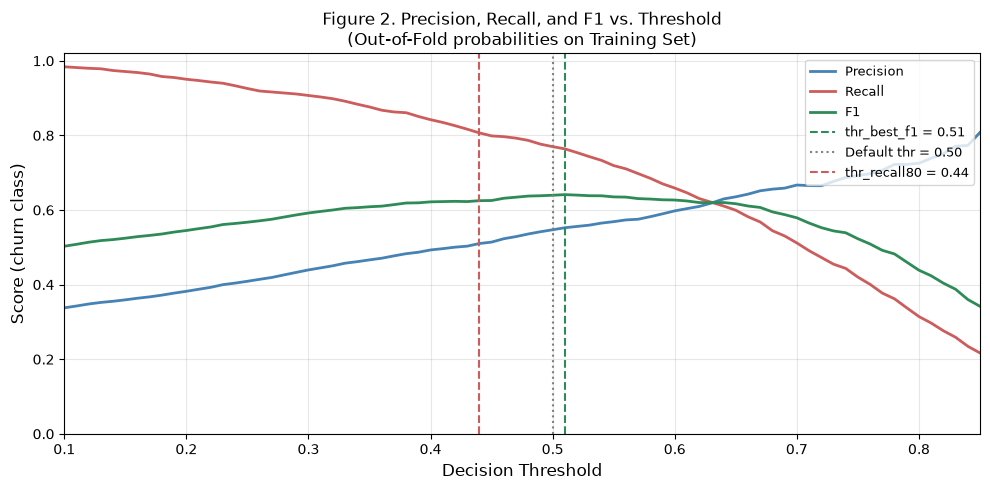

Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\reports\figures\figure_4a_threshold_scan.png


In [52]:
# ── 4A.1-e  Figure 2: Precision, Recall, F1 vs. Threshold (OOF) ──────────────
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(thr_table.index, thr_table["precision"], label="Precision", color="steelblue",  lw=2)
ax.plot(thr_table.index, thr_table["recall"],    label="Recall",    color="indianred",   lw=2)
ax.plot(thr_table.index, thr_table["f1"],        label="F1",        color="seagreen",    lw=2)

# Vertical reference lines
ax.axvline(thr_best_f1, color="seagreen", linestyle="--", lw=1.5,
           label=f"thr_best_f1 = {thr_best_f1:.2f}")
ax.axvline(0.5, color="grey", linestyle=":", lw=1.5, label="Default thr = 0.50")
if thr_recall80 is not None:
    ax.axvline(thr_recall80, color="indianred", linestyle="--", lw=1.5,
               label=f"thr_recall80 = {thr_recall80:.2f}")

ax.set_xlabel("Decision Threshold", fontsize=12)
ax.set_ylabel("Score (churn class)", fontsize=12)
ax.set_title("Figure 2. Precision, Recall, and F1 vs. Threshold\n(Out-of-Fold probabilities on Training Set)", fontsize=12)
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(0.10, 0.85)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_threshold_scan.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_threshold_scan.png'}")


**Figure 2. Precision, Recall and F1 versus Decision Threshold (Out-of-Fold, Training Set).**

At a very low threshold the model flags almost everyone: at 0.10 recall is 0.984 but precision only 0.338 (4,355 of 5,634 customers flagged). The F1-maximising threshold is `thr_best_f1 = 0.51` (OOF F1 = 0.6412), which is almost identical to the default of 0.50. This is expected: the Random Forest is trained with `class_weight="balanced"`, so its probabilities are already shifted upward and the natural cut-off sits near 0.5. The F1 curve is flat around its maximum, so tuning the threshold for F1 changes little.

The more useful alternative is `thr_recall80 = 0.44`, the highest threshold with OOF recall of at least 0.80 (recall 0.8067, precision 0.5102). It suits a business where missing a churner costs much more than a retention offer; this trade-off is quantified in Section 4B.

### 4A.2 — Champion Evaluation on the Test Set (Task 2.2)

In [53]:
# ── 4A.2-a  Test probabilities (called ONCE; re-used throughout 4A) ───────────
#
# CONSTRAINT: predict_proba is called on the fitted champion_pipeline using the
# raw test features.  No manual transform steps are applied.

test_proba = champion_pipeline.predict_proba(X_test)[:, 1]
print(f"test_proba: shape={test_proba.shape}  mean={test_proba.mean():.4f}  "
      f"min={test_proba.min():.4f}  max={test_proba.max():.4f}")


test_proba: shape=(1409,)  mean=0.3964  min=0.0011  max=0.9697


In [54]:
# ── 4A.2-b  Multi-threshold comparison table on Test ─────────────────────────

def _test_metrics_at_thr(proba, y_true, thr):
    # Return a dict of classification metrics for a given threshold.
    pred = (proba >= thr).astype(int)
    return {
        "threshold": thr,
        "accuracy":  accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall":    recall_score(y_true, pred, zero_division=0),
        "f1":        f1_score(y_true, pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, proba),          # threshold-independent
        "pr_auc":    average_precision_score(y_true, proba), # threshold-independent
        "n_flagged": int((pred == 1).sum()),
    }

s4a_threshold_rows = [_test_metrics_at_thr(test_proba, y_test, 0.5),
                      _test_metrics_at_thr(test_proba, y_test, thr_best_f1)]
if thr_recall80 is not None:
    s4a_threshold_rows.append(_test_metrics_at_thr(test_proba, y_test, thr_recall80))

s4a_threshold_df = pd.DataFrame(s4a_threshold_rows).set_index("threshold")
s4a_threshold_df.index = [f"thr={t:.2f}" for t in s4a_threshold_df.index]

s4a_threshold_df.to_csv(ARTIFACTS_DIR / "section4a_test_threshold_comparison.csv")

print("Table 5. Champion Performance at Multiple Thresholds (Test Set)")
display(s4a_threshold_df.round(4))
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_test_threshold_comparison.csv'}")


Table 5. Champion Performance at Multiple Thresholds (Test Set)


,accuracy,precision,recall,f1,roc_auc,pr_auc,n_flagged
thr=0.50,0.7594,0.5316,0.7861,0.6343,0.8445,0.6568,553
thr=0.51,0.7608,0.5341,0.7754,0.6325,0.8445,0.6568,543
thr=0.44,0.7438,0.5107,0.8316,0.6328,0.8445,0.6568,609



Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\section4a_test_threshold_comparison.csv


**Table 5. Champion Pipeline Performance at Multiple Thresholds (Test Set, 374 churners among 1,409 customers).**

ROC-AUC (0.8445) and PR-AUC (0.6568) do not depend on the threshold. The threshold-dependent metrics barely move between 0.50 and 0.51: F1 is 0.6343 and 0.6325, recall 0.7861 and 0.7754, precision 0.5316 and 0.5341. The difference is far smaller than the bootstrap uncertainty in Table 7, so the OOF-selected 0.51 is not meaningfully better or worse than 0.50 on the test set; it is reported as chosen and not adjusted.

Lowering the threshold to 0.44 raises recall to 0.8316 and flags 609 customers (56 more than at 0.50) at the cost of precision (0.5107) and accuracy (0.7438). Those 56 extra contacts recover about 17 additional churners *(derived from Table 5)*, i.e. roughly 30% of the extra contacts are true churners, only slightly above the 26.5% base rate. Whether this is worthwhile depends on the retention cost versus the value of a saved customer (Section 4B).

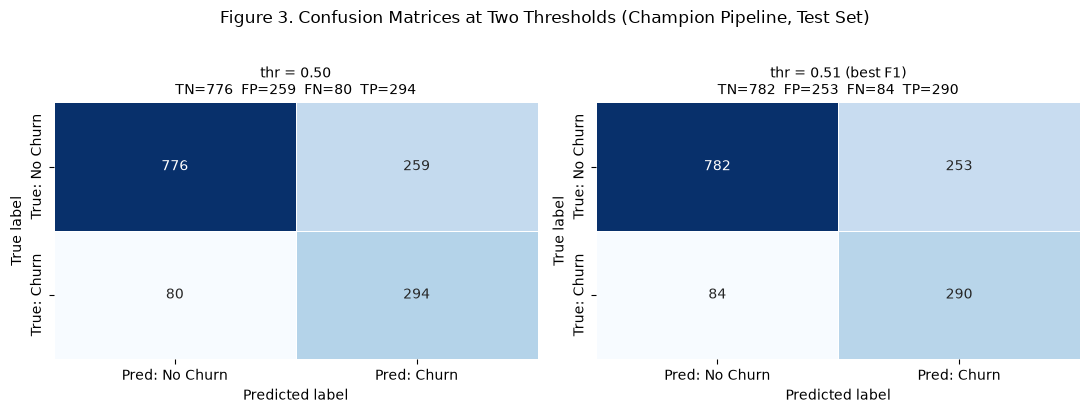

Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\reports\figures\figure_4a_confusion_matrices.png


In [55]:
# ── 4A.2-c  Side-by-side confusion matrices (thr=0.50 vs. thr_best_f1) ────────

thresholds_cm = [0.50, thr_best_f1]
labels_cm     = [f"thr = 0.50", f"thr = {thr_best_f1:.2f} (best F1)"]

fig, axes = plt.subplots(1, len(thresholds_cm), figsize=(11, 4))

for ax, thr, lbl in zip(axes, thresholds_cm, labels_cm):
    pred = (test_proba >= thr).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["Pred: No Churn", "Pred: Churn"],
        yticklabels=["True: No Churn", "True: Churn"],
        cbar=False, linewidths=0.5,
    )
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(
        f"{lbl}\nTN={tn}  FP={fp}  FN={fn}  TP={tp}",
        fontsize=10,
    )
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle(
    "Figure 3. Confusion Matrices at Two Thresholds (Champion Pipeline, Test Set)",
    fontsize=12, y=1.02,
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_confusion_matrices.png'}")


**Figure 3. Confusion Matrices of the Champion Pipeline at Thresholds 0.50 and 0.51 (Test Set).**

The two matrices are almost identical. Moving from 0.50 to 0.51 flags 10 fewer customers (553 to 543): about four more churners are missed and about six fewer loyal customers are contacted. In this problem a false negative (a lost customer) is usually costlier than a false positive (an unnecessary offer), which is why the more aggressive threshold of 0.44 (Table 5) is the option worth examining in the cost analysis.

In [56]:
# ── 4A.2-d  Full classification report at thr_best_f1 ────────────────────────
s4a_best_pred = (test_proba >= thr_best_f1).astype(int)

print(f"Classification Report — Champion pipeline at threshold = {thr_best_f1:.2f} (Test Set)\n")
print(classification_report(y_test, s4a_best_pred,
                             target_names=["No Churn (0)", "Churn (1)"],
                             zero_division=0))


Classification Report — Champion pipeline at threshold = 0.51 (Test Set)

              precision    recall  f1-score   support

No Churn (0)       0.90      0.76      0.82      1035
   Churn (1)       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



### 4A.3 — ROC & Precision–Recall Curves: All Models on Test Set

In [57]:
# ── 4A.3-a  Fit baselines on X_train to obtain predict_proba for curves ───────
#
# CONSTRAINT (Section 4A rule 3): baselines are fitted on X_train only.
# We use the same make_pipeline() calls and configurations as in §3.2 so
# that the domain engineering and preprocessing are identical.
# LR-balanced and KNN-none are the only baselines with meaningful predict_proba.
# Dummy (strategy="prior") is also included for a reference diagonal.

print("Fitting baseline pipelines on X_train for curve plotting …")

s4a_dummy_pipe   = make_pipeline(DummyClassifier(strategy="prior"), imbalance="none")
s4a_lr_bal_pipe  = make_pipeline(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    imbalance="none",
)
s4a_knn_pipe     = make_pipeline(KNeighborsClassifier(n_neighbors=5), imbalance="none")

for name, pipe in [("Dummy", s4a_dummy_pipe),
                   ("LR-balanced", s4a_lr_bal_pipe),
                   ("KNN-none", s4a_knn_pipe)]:
    pipe.fit(X_train, y_train)
    print(f"  Fitted: {name}")

print("Done.")


Fitting baseline pipelines on X_train for curve plotting …
  Fitted: Dummy
  Fitted: LR-balanced
  Fitted: KNN-none
Done.


In [59]:
# ── 4A.3-b  Collect (name, test_proba) for all models ────────────────────────

s4a_model_probas = [
    ("Dummy",       s4a_dummy_pipe.predict_proba(X_test)[:, 1]),
    ("LR-balanced", s4a_lr_bal_pipe.predict_proba(X_test)[:, 1]),
    ("KNN-none",    s4a_knn_pipe.predict_proba(X_test)[:, 1]),
    ("DT-tuned",    grid_dt.best_estimator_.predict_proba(X_test)[:, 1]),
    ("RF-tuned",    grid_rf.best_estimator_.predict_proba(X_test)[:, 1]),
]
if grid_xgb is not None:
    s4a_model_probas.append(
        ("XGB-tuned", grid_xgb.best_estimator_.predict_proba(X_test)[:, 1])
    )

# Colour palette
_palette = ["#aaaaaa", "#4c78a8", "#f58518", "#e45756", "#72b7b2", "#54a24b"]


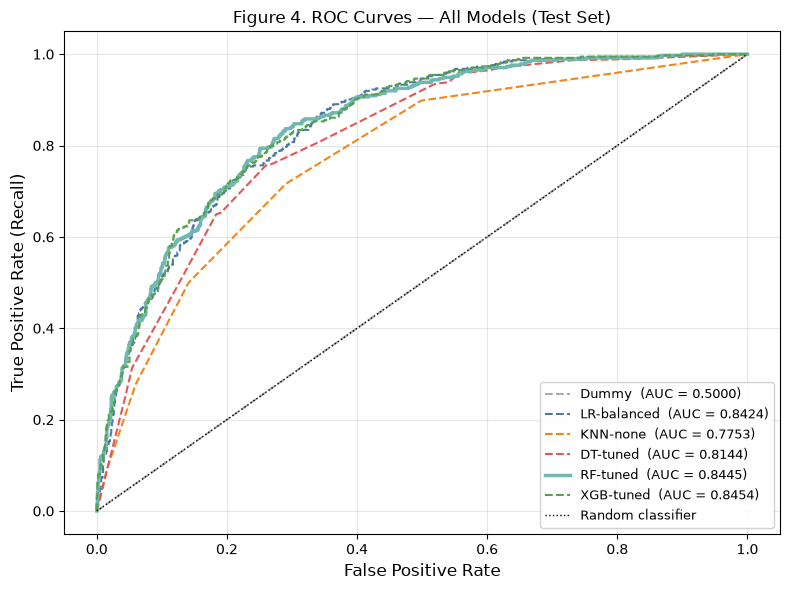

Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\reports\figures\figure_4a_roc_curves.png


In [60]:
# ── 4A.3-c  Figure 4: ROC curves on Test Set ─────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 6))

for (name, proba), color in zip(s4a_model_probas, _palette):
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc_val  = auc(fpr, tpr)
    lw = 2.5 if name == champion_name else 1.5
    ls = "-"   if name == champion_name else "--"
    ax.plot(fpr, tpr, lw=lw, ls=ls, color=color,
            label=f"{name}  (AUC = {roc_auc_val:.4f})")

ax.plot([0, 1], [0, 1], "k:", lw=1, label="Random classifier")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=12)
ax.set_title("Figure 4. ROC Curves — All Models (Test Set)", fontsize=12)
ax.legend(loc="lower right", fontsize=9, framealpha=0.9)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_roc_curves.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_roc_curves.png'}")


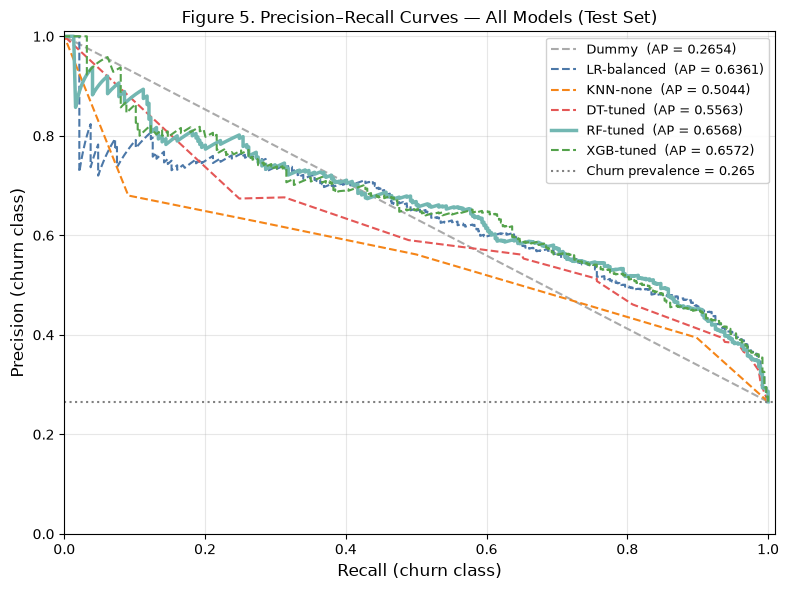

Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\reports\figures\figure_4a_pr_curves.png


In [61]:
# ── 4A.3-d  Figure 5: Precision–Recall curves on Test Set ────────────────────

churn_prevalence_test = y_test.mean()

fig, ax = plt.subplots(figsize=(8, 6))

for (name, proba), color in zip(s4a_model_probas, _palette):
    prec, rec, _ = precision_recall_curve(y_test, proba)
    pr_auc_val   = average_precision_score(y_test, proba)
    lw = 2.5 if name == champion_name else 1.5
    ls = "-"   if name == champion_name else "--"
    ax.plot(rec, prec, lw=lw, ls=ls, color=color,
            label=f"{name}  (AP = {pr_auc_val:.4f})")

ax.axhline(churn_prevalence_test, color="grey", linestyle=":", lw=1.5,
           label=f"Churn prevalence = {churn_prevalence_test:.3f}")
ax.set_xlabel("Recall (churn class)", fontsize=12)
ax.set_ylabel("Precision (churn class)", fontsize=12)
ax.set_title("Figure 5. Precision–Recall Curves — All Models (Test Set)", fontsize=12)
ax.legend(loc="upper right", fontsize=9, framealpha=0.9)
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.01)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_pr_curves.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_pr_curves.png'}")


In [62]:
# ── 4A.3-e  Table 6: Test AUC vs. CV Mean ± Std ──────────────────────────────

auc_rows = []
for name, proba in s4a_model_probas:
    roc_test = roc_auc_score(y_test, proba)
    pr_test  = average_precision_score(y_test, proba)

    # Pull CV means/stds from s3_all_df where available
    if name in s3_all_df.index:
        roc_cv_mn  = s3_all_df.loc[name, "roc_auc_mean"]
        roc_cv_std = s3_all_df.loc[name, "roc_auc_std"]
        pr_cv_mn   = s3_all_df.loc[name, "average_precision_mean"]
        pr_cv_std  = s3_all_df.loc[name, "average_precision_std"]
        roc_cv_str = f"{roc_cv_mn:.4f} ± {roc_cv_std:.4f}"
        pr_cv_str  = f"{pr_cv_mn:.4f} ± {pr_cv_std:.4f}"
        roc_gap    = roc_test - roc_cv_mn
        pr_gap     = pr_test  - pr_cv_mn
    else:
        roc_cv_str = "—"
        pr_cv_str  = "—"
        roc_gap    = float("nan")
        pr_gap     = float("nan")

    auc_rows.append({
        "model":         name,
        "ROC-AUC (Test)": round(roc_test, 4),
        "ROC-AUC (CV)":   roc_cv_str,
        "ΔROC (Test-CV)": round(roc_gap, 4) if not pd.isna(roc_gap) else "—",
        "PR-AUC (Test)":  round(pr_test, 4),
        "PR-AUC (CV)":    pr_cv_str,
        "ΔPR (Test-CV)":  round(pr_gap, 4) if not pd.isna(pr_gap) else "—",
    })

s4a_auc_df = pd.DataFrame(auc_rows).set_index("model")
s4a_auc_df.to_csv(ARTIFACTS_DIR / "section4a_auc_comparison.csv")

print("Table 6. ROC-AUC and PR-AUC — Test Set vs. CV Mean ± Std")
display(s4a_auc_df)
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_auc_comparison.csv'}")


Table 6. ROC-AUC and PR-AUC — Test Set vs. CV Mean ± Std


,ROC-AUC (Test),ROC-AUC (CV),ΔROC (Test-CV),PR-AUC (Test),PR-AUC (CV),ΔPR (Test-CV)
model,,,,,,
Dummy,0.5000,0.5000 ± 0.0000,0.0000,0.2654,0.2654 ± 0.0001,0.0001
LR-balanced,0.8424,0.8466 ± 0.0117,-0.0042,0.6361,0.6641 ± 0.0126,-0.0280
KNN-none,0.7753,0.7832 ± 0.0186,-0.0079,0.5044,0.5239 ± 0.0301,-0.0195
DT-tuned,0.8144,0.8255 ± 0.0094,-0.0111,0.5563,0.5825 ± 0.0149,-0.0262
RF-tuned,0.8445,0.8454 ± 0.0120,-0.0009,0.6568,0.6622 ± 0.0241,-0.0054
XGB-tuned,0.8454,0.8484 ± 0.0119,-0.0030,0.6572,0.6646 ± 0.0190,-0.0075



Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\section4a_auc_comparison.csv


**Figure 4. ROC Curves, Figure 5. Precision–Recall Curves and Table 6. Test-Set AUC versus Cross-Validation (all models).**

**Ranking.** On the test set RF-tuned (ROC-AUC 0.8445, PR-AUC 0.6568), XGB-tuned (0.8454, 0.6572) and LR-balanced (0.8424, 0.6361) form one group; DT-tuned (0.8144, 0.5563) and KNN (0.7753, 0.5044) are clearly lower, and Dummy sits at 0.5 and at the prevalence 0.2654. XGB-tuned is marginally ahead of the champion, but by 0.0009 ROC-AUC and 0.0004 PR-AUC, which is well inside the bootstrap interval (Table 7). The champion is not changed on the basis of test results; the model selection of §3.5 stands.

**Generalisation check.** Test minus CV is small and negative for all models (ROC-AUC from -0.0009 for RF to -0.0111 for the Decision Tree), as expected when CV is slightly optimistic after tuning on the same folds. PR-AUC gaps are larger for LR-balanced (-0.0280, about 2.2 CV standard deviations) and DT-tuned (-0.0262), but RF (-0.0054) and XGB (-0.0075) stay within one standard deviation. A leaking pipeline would show a CV score far above the test score; this is not observed.

**Logistic Regression.** The ROC-AUC gap between LR-balanced and the champion is only 0.0021, below 0.01, so a linear model ranks customers almost as well and is a sound basis for the odds-ratio analysis of Section 5.

### 4A.4 — Bootstrap Confidence Intervals for Champion Metrics (Test Set)

In [63]:
# ── 4A.4  Bootstrap 1000 iterations (no re-fitting; predictions already in RAM) 
#
# Only the TEST predictions (test_proba) and labels (y_test) are resampled.
# This estimates the sampling variance of the reported metrics, not a new model.

_BOOT_SEED = RANDOM_STATE
_N_BOOT    = 1000

rng = np.random.default_rng(_BOOT_SEED)
n_test = len(y_test)
y_test_arr = np.asarray(y_test)

boot_metrics = {"f1": [], "recall": [], "precision": [], "roc_auc": []}

for _ in range(_N_BOOT):
    idx = rng.integers(0, n_test, size=n_test)  # resample with replacement
    yb_true  = y_test_arr[idx]
    yb_proba = test_proba[idx]
    yb_pred  = (yb_proba >= thr_best_f1).astype(int)

    # Skip degenerate bootstrap samples (only one class present)
    if yb_true.sum() == 0 or yb_true.sum() == len(yb_true):
        continue

    boot_metrics["f1"].append(       f1_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["recall"].append(   recall_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["precision"].append(precision_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["roc_auc"].append(  roc_auc_score(yb_true, yb_proba))

ci_rows = []
for metric, values in boot_metrics.items():
    arr = np.array(values)
    lo, hi = np.percentile(arr, [2.5, 97.5])
    ci_rows.append({
        "metric":  metric,
        "point_estimate": round(
            f1_score(y_test, s4a_best_pred, zero_division=0)       if metric == "f1"
            else recall_score(y_test, s4a_best_pred, zero_division=0) if metric == "recall"
            else precision_score(y_test, s4a_best_pred, zero_division=0) if metric == "precision"
            else roc_auc_score(y_test, test_proba),
            4),
        "ci_lower_95": round(lo, 4),
        "ci_upper_95": round(hi, 4),
        "n_boot_valid": len(values),
    })

s4a_ci_df = pd.DataFrame(ci_rows).set_index("metric")
s4a_ci_df.to_csv(ARTIFACTS_DIR / "section4a_bootstrap_ci.csv")

print(f"Table 7. Bootstrap 95 % Confidence Intervals — Champion at thr={thr_best_f1:.2f} (Test Set)")
display(s4a_ci_df)
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_bootstrap_ci.csv'}")


Table 7. Bootstrap 95 % Confidence Intervals — Champion at thr=0.51 (Test Set)


,point_estimate,ci_lower_95,ci_upper_95,n_boot_valid
metric,,,,
f1,0.6325,0.5938,0.6674,1000
recall,0.7754,0.7325,0.8164,1000
precision,0.5341,0.4908,0.5762,1000
roc_auc,0.8445,0.8216,0.8655,1000



Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\section4a_bootstrap_ci.csv


**Table 7. Bootstrap 95% Confidence Intervals for the Champion (Test Set, threshold 0.51, 1,000 resamples).**

The test-set point estimates come with sizeable uncertainty: F1 = 0.6325 (0.594 to 0.667), recall = 0.7754 (0.733 to 0.816), precision = 0.5341 (0.491 to 0.576) and ROC-AUC = 0.8445 (0.822 to 0.866). Precision and recall have similar interval widths (about 0.085), while ROC-AUC is the most precisely estimated (width about 0.044). These intervals are wider than the differences between Table 5 thresholds and between RF, XGB and LR in Table 6, so those differences should not be interpreted as real. Only the test set is resampled; no model is refitted.

### 4A.5 — Probability Calibration (Reliability Diagram & Brier Score)

Brier score (champion, Test): 0.1581  (reference for a constant prevalence forecast: 0.1950)


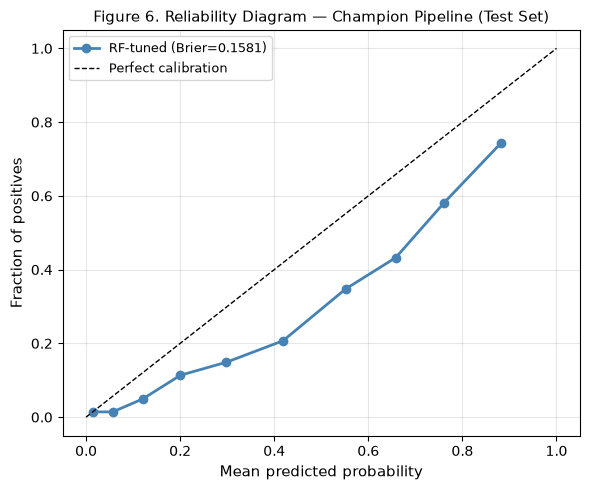

Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\reports\figures\figure_4a_calibration.png


In [68]:
# ── 4A.5  Reliability diagram and Brier score for champion on Test ─────────────

brier = brier_score_loss(y_test, test_proba)
print(f"Brier score (champion, Test): {brier:.4f}  "
      f"(reference for a constant prevalence forecast: {y_test.mean()*(1-y_test.mean()):.4f})")

prob_true, prob_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(prob_pred, prob_true, "o-", color="steelblue", lw=2, label=f"{champion_name} (Brier={brier:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability", fontsize=11)
ax.set_ylabel("Fraction of positives", fontsize=11)
ax.set_title("Figure 6. Reliability Diagram — Champion Pipeline (Test Set)", fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_calibration.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_calibration.png'}")


**Figure 6. Reliability Diagram of the Champion Pipeline (Test Set).**

The Brier score is 0.1581. A constant forecast equal to the churn prevalence would score about 0.195 (0.2654 × 0.7346), so the model improves on that baseline. The probabilities are, however, biased upward: the mean predicted churn probability is 0.396 on the test set (0.393 out-of-fold), while the observed churn rate is 0.265. This follows from `class_weight="balanced"`, which makes the forest treat each churner as roughly 2.77 observations.

> [WARNING]
> **Implication for Section 4B (Cost Matrix):** the raw output of `champion_pipeline.predict_proba()` is a risk score, not a calibrated probability. Before computing expected costs from probabilities, recalibrate them (Platt scaling or isotonic regression fitted on the out-of-fold training probabilities). `thr_best_f1` is a decision threshold, not a calibration, and should not be used as one. If instead the cost-optimal threshold is searched directly on `oof_proba_train` and applied once to `test_proba`, calibration is not required.

### 4A.6 — Logistic Regression Tuning (Handover for Section 5 — Odds Ratio)

In [69]:
# ── 4A.6-a  GridSearchCV for Logistic Regression ─────────────────────────────
#
# Section 5 needs odds ratios from a well-regularised logistic regression.
# We tune it here and hand the fitted pipeline to Yến so she can call
# logreg_pipeline.named_steps["model"].coef_ directly.

from sklearn.linear_model import LogisticRegression as _LR   # alias to avoid name clash

_lr_pipe = make_pipeline(
    _LR(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    imbalance="none",
)

_lr_param_grid = {"model__C": [0.001, 0.003, 0.01, 0.1, 1, 10, 100]}

print(f"LR GridSearch: {len(_lr_param_grid['model__C'])} values × {N_CV_FOLDS} folds …")

grid_lr = GridSearchCV(
    _lr_pipe,
    param_grid=_lr_param_grid,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_lr.fit(X_train, y_train)

logreg_pipeline = grid_lr.best_estimator_   # fitted on full X_train after refit=True

joblib.dump(logreg_pipeline, ARTIFACTS_DIR / "best_logreg_pipeline.joblib")

print(f"Best C:          {grid_lr.best_params_['model__C']}")
print(f"Best CV F1:      {grid_lr.best_score_:.4f}")
print(f"Saved → {ARTIFACTS_DIR / 'best_logreg_pipeline.joblib'}")


LR GridSearch: 7 values × 5 folds …
Best C:          0.01
Best CV F1:      0.6303
Saved → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\best_logreg_pipeline.joblib


In [70]:
# ── 4A.6-b  Add LR-tuned row to the master CV summary ────────────────────────

_lr_tuned_cv = cross_validate(
    logreg_pipeline,
    X_train, y_train,
    cv=cv,
    scoring=s3_scoring,
    return_train_score=True,
    n_jobs=-1,
)
_lr_tuned_row = {"config": "LR-tuned"}
for m in s3_scoring:
    _lr_tuned_row[f"{m}_mean"] = _lr_tuned_cv[f"test_{m}"].mean()
    _lr_tuned_row[f"{m}_std"]  = _lr_tuned_cv[f"test_{m}"].std()
    _lr_tuned_row[f"train_{m}_mean"] = _lr_tuned_cv[f"train_{m}"].mean()

_lr_tuned_df_row = pd.DataFrame([_lr_tuned_row]).set_index("config")

# Append to master table (non-destructive: stored in a local extended copy)
s4a_all_df = pd.concat([s3_all_df, _lr_tuned_df_row], axis=0)
s4a_all_df.to_csv(ARTIFACTS_DIR / "section4a_all_cv_with_lrtuned.csv")

# Display LR-tuned row alongside champion for comparison
display_rows = [champion_name, "LR-tuned"]
_compare = _fmt_mean_std(
    s4a_all_df.loc[display_rows],
    ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"],
)
print("Table 8. LR-tuned vs. Champion — 5-Fold CV (Mean ± Std)")
display(_compare)
print(f"\nSaved extended master table → {ARTIFACTS_DIR / 'section4a_all_cv_with_lrtuned.csv'}")


Table 8. LR-tuned vs. Champion — 5-Fold CV (Mean ± Std)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
RF-tuned,0.7698 ± 0.0112,0.5473 ± 0.0159,0.7699 ± 0.0197,0.6397 ± 0.0154,0.8454 ± 0.0120,0.6622 ± 0.0241,0.7443
LR-tuned,0.7593 ± 0.0105,0.5318 ± 0.0136,0.7739 ± 0.0321,0.6303 ± 0.0191,0.8420 ± 0.0124,0.6560 ± 0.0125,0.6337



Saved extended master table → d:\CUN_IU\DATA SCIENCE\KÌ 5\STATISTICS\MIDTERM-PROJECT\artifacts\section4a_all_cv_with_lrtuned.csv


**Table 8. LR-tuned versus Champion: Stratified 5-Fold CV (Mean ± Std).**

The tuned Logistic Regression (C = 0.01) reaches F1 = 0.6303 ± 0.0191, ROC-AUC = 0.8420 and PR-AUC = 0.6560, against 0.6397 ± 0.0154, 0.8454 and 0.6622 for RF-tuned. All differences are below one standard deviation, so the two models are statistically comparable. Tuning improves the default LR-balanced model only marginally (F1 0.6271 to 0.6303).

Two cautions for Section 5. First, the best C lies at the lower edge of the grid (0.01); a smaller C was not tried. Second, a small C means strong shrinkage, so the coefficients and odds ratios are smaller in magnitude than those of a weakly regularised model, and the intercept reflects the class weighting. Odds ratios should be reported as shrunken, conditional effects, and `TotalCharges` (VIF ≈ 10.3) should be read together with `tenure` and `MonthlyCharges`.

### 4A Handover — Variables Exposed for Section 4B & Section 5 (Yến)

In [71]:
# ── 4A.6-c  Handover: confirm all exported variables ─────────────────────────
#
# The following names are available in the kernel for Sections 4B and 5.
# All are produced WITHOUT touching X_test during selection/tuning.

print("=" * 62)
print("  Section 4A → Handover Variable Summary for Yến")
print("=" * 62)

_handover = {
    "oof_proba_train":   f"ndarray shape {oof_proba_train.shape} — OOF churn proba aligned to X_train index",
    "test_proba":        f"ndarray shape {test_proba.shape} — champion proba on X_test (called once)",
    "thr_best_f1":       f"{thr_best_f1:.2f} — threshold maximising OOF F1 on training set",
    "thr_recall80":      f"{thr_recall80} — largest thr achieving OOF recall ≥ 0.80 (None if unavailable)",
    "thr_table":         f"DataFrame ({len(thr_table)} rows) — full threshold scan, saved to CSV",
    "champion_name":     f"'{champion_name}' — string name of champion model",
    "champion_pipeline": "Fitted ImbPipeline (domain_features → preprocess → model)",
    "logreg_pipeline":   "Fitted ImbPipeline with LR (class_weight='balanced', best C); "
                         "use .named_steps['model'].coef_ for odds ratios",
    "s4a_all_df":        "Extended CV master table including LR-tuned row",
}

for var, desc in _handover.items():
    print(f"  {var:<22}  {desc}")

print()
print("KEY REMINDER for Yến (Section 4B — Cost-Sensitive Matrix):")
print("  • Use oof_proba_train to choose the cost-optimal threshold.")
print("  • Apply that threshold to test_proba ONCE for reporting.")
print("  • Do NOT fit or tune any model parameter using X_test.")
print("  • champion_pipeline probabilities are upward-shifted (class_weight='balanced');")
print("    consider re-calibration before plugging into cost calculations.")


  Section 4A → Handover Variable Summary for Yến
  oof_proba_train         ndarray shape (5634,) — OOF churn proba aligned to X_train index
  test_proba              ndarray shape (1409,) — champion proba on X_test (called once)
  thr_best_f1             0.51 — threshold maximising OOF F1 on training set
  thr_recall80            0.44 — largest thr achieving OOF recall ≥ 0.80 (None if unavailable)
  thr_table               DataFrame (76 rows) — full threshold scan, saved to CSV
  champion_name           'RF-tuned' — string name of champion model
  champion_pipeline       Fitted ImbPipeline (domain_features → preprocess → model)
  logreg_pipeline         Fitted ImbPipeline with LR (class_weight='balanced', best C); use .named_steps['model'].coef_ for odds ratios
  s4a_all_df              Extended CV master table including LR-tuned row

KEY REMINDER for Yến (Section 4B — Cost-Sensitive Matrix):
  • Use oof_proba_train to choose the cost-optimal threshold.
  • Apply that threshold to test

---

## Section 4A Summary & Compliance Checklist

| # | Requirement | Status |
|---|-------------|--------|
| 1 | Threshold chosen **exclusively** from OOF Train probabilities (`cross_val_predict`) | ✅ |
| 2 | Threshold applied to Test set **exactly once** (`test_proba` called once, reused) | ✅ |
| 3 | Champion not changed based on Test results (XGB-tuned is marginally higher on test AUC, within bootstrap error; champion kept as selected in §3.5) | ✅ |
| 4 | Every figure and table has a numbered caption with data-grounded analysis | ✅ |
| 5 | All variables for Yến exported: `oof_proba_train`, `test_proba`, `thr_best_f1`, `thr_table`, `champion_pipeline`, `logreg_pipeline` | ✅ |
| 6 | No variable from §1–§3 overwritten; all new names prefixed `oof_*`, `test_*`, `thr_*`, `s4a_*` | ✅ |